# Conversation surprisal: dynamics, speaker roles and topic shifts

Analysis of the token-level surprisals produced by `conversation_surprisal.py`.

**Inputs**
- `SURPRISALS`: output of `conversation_surprisal.py --context global` (every turn conditioned on the preceding conversation)
- `LOCAL_SURPRISALS` *(optional)*: output of `--context local` (every turn scored alone); enables PMI
- `METADATA`: the original conversations CSV (topic annotations, timing, utterance text)

**Definitions**

| quantity | meaning |
|---|---|
| global surprisal $s_g$ | $-\log_2 p(\text{token}\mid \text{preceding conversation} + \text{same-turn prefix})$ |
| local surprisal $s_l$ | $-\log_2 p(\text{token}\mid \text{same-turn prefix only})$ |
| PMI | $s_l - s_g = \log_2 p(\text{tok}\mid\text{global}) - \log_2 p(\text{tok}\mid\text{local})$. Positive: earlier conversation made the token *more* predictable |
| rolling mean | mean of $s$ over $w$ tokens ($w=3,5,7$), within a turn by default (`ROLL_SCOPE`) |
| turn mean / sum | mean / sum of token surprisals over the turn |

**Caveats.** (1) The first speaker of every conversation is always the `user` role, so *role* mixes template framing with who opens the conversation. (2) Turn 0 is sometimes a pooled block of backchannels and can skew turn sums.

In [21]:
import re, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

%matplotlib inline
plt.rcParams.update({"figure.max_open_warning": 0})


# ============================== CONFIG ==============================
SURPRISALS       = "surprisals_test_2convs.csv.gz"                          # <-- SET ME
SURPRISALS_BASE = "surprisals_test_llama-8b-base.csv.gz"                  # <-- SET ME
LOCAL_SURPRISALS = None                          # <-- SET ME (or None to skip PMI)
METADATA         = "dense_subset1_and_subset2_processed.csv"  # <-- SET ME
OUTDIR           = "analysis_out"

# which conversations get line plots
TRANSCRIPTS       = None     # e.g. ["31a7caa4-f825-4995-8d4d-2126124ff47c"]; None -> random sample
N_CONVERSATIONS   = 5
ALL_CONVERSATIONS = False    # True -> every conversation (saved to disk; only INLINE_MAX shown)
SEED              = 0

# aggregation
ROLLING     = [3, 5, 7]
ROLL_SCOPE  = "turn"         # "turn": roll within each turn | "speaker": over a speaker's whole token stream
ROLL_MODE   = "centered"     # "centered" | "trailing"

# line plots
PAGE_TURNS = 500             # turns per figure
ZOOM       = None            # e.g. (260, 285): shaded in the full figure + extra zoomed figure
INLINE_MAX = 6               # max line-plot figures displayed inline (all are saved)

# topic-shift event study
EVENT_WINDOW           = 6
MIN_ANNOTATORS         = [1, 2]
KEEP_START_CALL_SHIFTS = False   # keep shifts with previous_topic == "Starting The Call"
N_RESAMPLES            = 300     # bootstrap / permutation iterations

TOP_N = 300
DPI   = 110
# ====================================================================

RUN_LABEL = ""   # filled from the data below; appears in figure titles
KEYS = ["transcript_id", "turn_id"]
C1, C2 = "#1f77b4", "#ff7f0e"        # first / second speaker of every conversation
OUT = Path(OUTDIR)
(OUT / "lineplots").mkdir(parents=True, exist_ok=True)

_shown = {"n": 0}
def finish(fig, path, limited=False):
    """Save the figure and show it inline (line plots are capped by INLINE_MAX)."""
    fig.savefig(path, bbox_inches="tight")
    if not limited or _shown["n"] < INLINE_MAX:
        plt.show()
        _shown["n"] += limited
    plt.close(fig)

## 1. Load data

In [3]:
def load_tokens(path, local_path=None):
    g = pd.read_csv(path, dtype={"transcript_id": str})
    g = g.sort_values(KEYS + ["token_idx"], kind="stable").reset_index(drop=True)
    g["has_pmi"] = False
    if local_path:
        l = pd.read_csv(local_path, dtype={"transcript_id": str})
        for k in ("model", "unit", "format_mode", "bow_correction"):  # global and local runs must be comparable
            if k in g.columns and k in l.columns and g[k].iloc[0] != l[k].iloc[0]:
                raise ValueError(f"global and local runs differ in {k}: {g[k].iloc[0]!r} vs {l[k].iloc[0]!r}")
        l = l[KEYS + ["token_idx", "token_id", "surprisal"]]
        l = l.rename(columns={"surprisal": "s_local", "token_id": "token_id_local"})
        g = g.merge(l, on=KEYS + ["token_idx"], how="left")
        bad = g["s_local"].notna() & (g["token_id"] != g["token_id_local"])
        miss = g["s_local"].isna().sum()
        if bad.any() or miss:
            warnings.warn(f"local run: {bad.sum()} tokens with different tokenisation and {miss} missing tokens "
                          "-> PMI set to NaN for those tokens")
        g.loc[bad, "s_local"] = np.nan
        g["pmi"] = g["s_local"] - g["surprisal"]
        g = g.drop(columns="token_id_local")
        g["has_pmi"] = True
    g["n_tokens"] = g.groupby(KEYS)["surprisal"].transform("size")
    g["x_tok"] = g["turn_id"] + (g["token_idx"] + 0.5) / g["n_tokens"]
    return g


def load_metadata(path):
    m = pd.read_csv(path, dtype={"transcript_id": str})
    for c in ("new_topic", "previous_topic"):
        m[c] = m[c].astype("object").where(m[c].notna(), None)
        m[c] = m[c].map(lambda s: s.strip() if isinstance(s, str) and s.strip() else None)
    # --- topic annotations: several annotators (rows) can mark the same turn
    t = m[m["new_topic"].notna() | m["previous_topic"].notna()].copy()
    ann_col = "participent_id" if "participent_id" in t.columns else None
    grp = t.groupby(KEYS)
    marks = pd.DataFrame({
        "n_annot": grp[ann_col].nunique() if ann_col else grp.size(),
        "new_topics": grp["new_topic"].agg(lambda s: " | ".join(sorted({x for x in s if x}))),
        "previous_topics": grp["previous_topic"].agg(lambda s: " | ".join(sorted({x for x in s if x}))),
        "is_start_call": grp["previous_topic"].agg(
            lambda s: all((x or "").lower() == "starting the call" for x in s)),
    }).reset_index()
    # --- one row per turn
    cols = [c for c in ["start", "stop", "n_words", "overlap", "backchannel_count", "utterance"] if c in m.columns]
    turns = m.drop_duplicates(KEYS).sort_values(KEYS)[KEYS + cols].reset_index(drop=True)
    turns["utterance"] = turns["utterance"].fillna("").astype(str).map(lambda s: re.sub(r"\s+", " ", s).strip())
    return turns, marks

In [4]:
d = load_tokens(SURPRISALS, LOCAL_SURPRISALS)
turns, marks = load_metadata(METADATA)
has_pmi = bool(d["has_pmi"].iloc[0])
roles = sorted(d["role"].unique(), key=lambda r: {"user": 0, "assistant": 1, "A": 0, "B": 1}.get(r, 9))
run_info = {k: d[k].iloc[0] for k in ("model", "context", "format_mode", "unit", "bow_correction") if k in d.columns}
RUN_LABEL = " / ".join(str(run_info[k]) for k in ("model", "format_mode", "unit") if k in run_info)
print("scoring run:", run_info if run_info else "(no run metadata in file; re-score with the current conversation_surprisal.py)")
print(f"{len(d):,} tokens | {d.transcript_id.nunique()} conversations | PMI available: {has_pmi} | roles: {roles}")
print(f"{len(marks):,} annotated topic-shift turns in {marks.transcript_id.nunique()} conversations")
d.head()

scoring run: (no run metadata in file; re-score with the current conversation_surprisal.py)
1,030,294 tokens | 155 conversations | PMI available: False | roles: ['user', 'assistant']
5,243 annotated topic-shift turns in 155 conversations


,transcript_id,turn_id,speaker,role,window_id,n_prior_tokens,token_idx,token_id,token,char_start,char_end,surprisal,has_pmi,n_tokens,x_tok
0,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,user,0,30,0,1799,char,0,4,10.750,False,11,0.045455
1,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,user,0,30,1,11828,lie,4,7,1.500,False,11,0.136364
2,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,user,0,30,2,11,",",7,8,6.125,False,11,0.227273
3,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,user,0,30,3,3868,Ġwait,8,13,9.625,False,11,0.318182
4,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,user,0,30,4,11,",",13,14,1.625,False,11,0.409091


In [22]:
d_base = load_tokens(SURPRISALS_BASE, LOCAL_SURPRISALS)
roles_base = sorted(d_base["role"].unique(), key=lambda r: {"user": 0, "assistant": 1, "A": 0, "B": 1}.get(r, 9))
run_info_base = {k: d_base[k].iloc[0] for k in ("model", "context", "format_mode", "unit", "bow_correction") if k in d_base.columns}
RUN_LABEL_BASE = " / ".join(str(run_info_base[k]) for k in ("model", "format_mode", "unit") if k in run_info_base)
print("scoring run:", run_info_base if run_info_base else "(no run metadata in file; re-score with the current conversation_surprisal.py)")
print(f"{len(d_base):,} tokens | {d_base.transcript_id.nunique()} conversations | PMI available: {has_pmi} | roles: {roles_base}")
print(f"{len(marks):,} annotated topic-shift turns in {marks.transcript_id.nunique()} conversations")
d_base.head()

scoring run: (no run metadata in file; re-score with the current conversation_surprisal.py)
1,027,276 tokens | 155 conversations | PMI available: False | roles: ['A', 'B']
5,243 annotated topic-shift turns in 155 conversations


,transcript_id,turn_id,speaker,role,window_id,n_prior_tokens,token_idx,token_id,token,char_start,char_end,surprisal,has_pmi,n_tokens,x_tok
0,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,A,0,3,0,1181,Ġchar,0,4,14.1250,False,11,0.045455
1,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,A,0,3,1,11828,lie,4,7,2.6250,False,11,0.136364
2,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,A,0,3,2,11,",",7,8,3.1250,False,11,0.227273
3,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,A,0,3,3,3868,Ġwait,8,13,8.8750,False,11,0.318182
4,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,A,0,3,4,11,",",13,14,1.6875,False,11,0.409091


## 2. Aggregations

Token-level rolling means (3/5/7 tokens), turn-level mean/sum/max, and PMI. `turn_level.csv.gz` is written to the output folder for further analysis.

In [5]:
def grouped_rolling(values, gid, w, mode="centered"):
    """Rolling mean of `values` inside contiguous groups `gid`; NaN-aware; truncated windows at group edges."""
    n = len(values)
    idx = np.arange(n)
    starts = np.flatnonzero(np.r_[True, gid[1:] != gid[:-1]])
    ends = np.r_[starts[1:], n]
    gs, ge = np.repeat(starts, ends - starts), np.repeat(ends, ends - starts)
    if mode == "centered":
        lo, hi = idx - w // 2, idx + (w - 1 - w // 2)
    else:  # trailing
        lo, hi = idx - (w - 1), idx
    lo, hi = np.maximum(lo, gs), np.minimum(hi, ge - 1)
    ok = ~np.isnan(values)
    cs = np.r_[0.0, np.cumsum(np.where(ok, values, 0.0))]
    cc = np.r_[0, np.cumsum(ok)]
    den = cc[hi + 1] - cc[lo]
    return np.where(den > 0, (cs[hi + 1] - cs[lo]) / np.maximum(den, 1), np.nan)


def add_rolling(d, col, ws, scope, mode):
    tr = pd.factorize(d["transcript_id"])[0]
    if scope == "turn":
        order = np.lexsort((d["token_idx"].values, d["turn_id"].values, tr))
        gkey = tr.astype(np.int64) * 10_000_000 + d["turn_id"].values
    else:  # speaker stream
        spk = pd.factorize(d["speaker"])[0]
        order = np.lexsort((d["token_idx"].values, d["turn_id"].values, spk, tr))
        gkey = tr.astype(np.int64) * 1000 + spk
    vals, gid = d[col].values.astype(float)[order], gkey[order]
    for w in ws:
        out = np.empty(len(d))
        out[order] = grouped_rolling(vals, gid, w, mode)
        d[f"{col}_roll{w}"] = out
    return d


def turn_table(d, turns, marks):
    agg = dict(speaker=("speaker", "first"), role=("role", "first"), n_tokens=("surprisal", "size"),
               surprisal_mean=("surprisal", "mean"), surprisal_sum=("surprisal", "sum"),
               surprisal_max=("surprisal", "max"), n_prior_tokens=("n_prior_tokens", "first"))
    if d["has_pmi"].iloc[0]:
        agg.update(pmi_mean=("pmi", "mean"), pmi_sum=("pmi", "sum"), s_local_mean=("s_local", "mean"))
    t = d.groupby(KEYS, sort=True).agg(**agg).reset_index()
    t = t.merge(turns, on=KEYS, how="left").merge(marks, on=KEYS, how="left")
    t["n_annot"] = t["n_annot"].fillna(0).astype(int)
    t["is_start_call"] = t["is_start_call"].fillna(False).astype(bool)
    t["pos"] = t.groupby("transcript_id").cumcount()
    t["rel_pos"] = t["pos"] / t.groupby("transcript_id")["pos"].transform("max").clip(lower=1)
    if {"start", "stop"} <= set(t.columns):
        t["duration"] = t["stop"] - t["start"]
        t["bits_per_sec"] = t["surprisal_sum"] / t["duration"].where(t["duration"] > 0)
    return t

In [6]:
d = add_rolling(d, "surprisal", ROLLING, ROLL_SCOPE, ROLL_MODE)
if has_pmi:
    d = add_rolling(d, "pmi", ROLLING, ROLL_SCOPE, ROLL_MODE)
t = turn_table(d, turns, marks)
t.to_csv(OUT / "turn_level.csv.gz", index=False)
t.head()

/var/folders/fn/6ct_6l112376k8288ws7798m0000gn/T/ipykernel_54583/282643040.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  t["is_start_call"] = t["is_start_call"].fillna(False).astype(bool)


,transcript_id,turn_id,speaker,role,n_tokens,surprisal_mean,surprisal_sum,surprisal_max,n_prior_tokens,start,...,backchannel_count,utterance,n_annot,new_topics,previous_topics,is_start_call,pos,rel_pos,duration,bits_per_sec
0,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,user,11,4.431818,48.7500,10.7500,30,48.54,...,0,"charlie, wait, hi, can you hear me",0,NaN,NaN,False,0,0.000000,3.52,13.849432
1,01a4c01c-cf0e-4f37-ab2b-641bb604af30,1,5f1b2282a3103e2caff2fd7b,assistant,8,7.726562,61.8125,13.2500,46,52.34,...,1,"Yes, we did. Okay me.",0,NaN,NaN,False,1,0.001681,1.22,50.665984
2,01a4c01c-cf0e-4f37-ab2b-641bb604af30,2,5e6cade3d92ffb26677dbd84,user,9,5.979167,53.8125,15.6875,59,53.72,...,1,"Yeah, I can hold on sorry to like",0,NaN,NaN,False,2,0.003361,2.89,18.620242
3,01a4c01c-cf0e-4f37-ab2b-641bb604af30,3,5f1b2282a3103e2caff2fd7b,assistant,3,8.229167,24.6875,12.3125,73,56.26,...,0,that works.,0,NaN,NaN,False,3,0.005042,0.60,41.145833
4,01a4c01c-cf0e-4f37-ab2b-641bb604af30,4,5e6cade3d92ffb26677dbd84,user,61,3.586066,218.7500,11.5000,81,56.62,...,2,go in the bathroom because my boyfriend's play...,1,Homey room intrusion,Starting The Call,True,4,0.006723,21.44,10.202892


In [23]:
d_base = add_rolling(d_base, "surprisal", ROLLING, ROLL_SCOPE, ROLL_MODE)
if has_pmi:
    d_base = add_rolling(d_base, "pmi", ROLLING, ROLL_SCOPE, ROLL_MODE)
t_base = turn_table(d_base, turns, marks)
t_base.to_csv(OUT / "turn_level_base.csv.gz", index=False)
t_base.head()

/var/folders/fn/6ct_6l112376k8288ws7798m0000gn/T/ipykernel_54583/282643040.py:46: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  t["is_start_call"] = t["is_start_call"].fillna(False).astype(bool)


,transcript_id,turn_id,speaker,role,n_tokens,surprisal_mean,surprisal_sum,surprisal_max,n_prior_tokens,start,...,backchannel_count,utterance,n_annot,new_topics,previous_topics,is_start_call,pos,rel_pos,duration,bits_per_sec
0,01a4c01c-cf0e-4f37-ab2b-641bb604af30,0,5e6cade3d92ffb26677dbd84,A,11,4.272727,47.0000,14.1250,3,48.54,...,0,"charlie, wait, hi, can you hear me",0,NaN,NaN,False,0,0.000000,3.52,13.352273
1,01a4c01c-cf0e-4f37-ab2b-641bb604af30,1,5f1b2282a3103e2caff2fd7b,B,8,4.703125,37.6250,9.5625,17,52.34,...,1,"Yes, we did. Okay me.",0,NaN,NaN,False,1,0.001681,1.22,30.840164
2,01a4c01c-cf0e-4f37-ab2b-641bb604af30,2,5e6cade3d92ffb26677dbd84,A,9,4.277778,38.5000,8.1875,27,53.72,...,1,"Yeah, I can hold on sorry to like",0,NaN,NaN,False,2,0.003361,2.89,13.321799
3,01a4c01c-cf0e-4f37-ab2b-641bb604af30,3,5f1b2282a3103e2caff2fd7b,B,3,4.895833,14.6875,6.5625,39,56.26,...,0,that works.,0,NaN,NaN,False,3,0.005042,0.60,24.479167
4,01a4c01c-cf0e-4f37-ab2b-641bb604af30,4,5e6cade3d92ffb26677dbd84,A,61,2.985656,182.1250,11.2500,44,56.62,...,2,"go in the bathroom because my boyfriend's playing guitar right now, he's practicing stuff. I'm like cooped up in my ...",1,Homey room intrusion,Starting The Call,True,4,0.006723,21.44,8.494636


## 3. Line plots with topic-shift marks

One figure per conversation (split into pages of `PAGE_TURNS` turns). One line per speaker; x axis = turn (token-level lines are placed at their fractional position inside the turn). **Black vertical lines** mark turns where an annotator flagged a topic shift; thicker lines = more annotators agree.

In [7]:
def build_panels(ws, has_pmi):
    P = [("turn_mean", "Turn mean surprisal (bits)", "turn", "surprisal_mean", None),
         ("turn_sum", "Turn summed surprisal (bits)", "turn", "surprisal_sum", None),
         ("tok_raw", "Token surprisal (bits)", "tok", "surprisal", None)]
    P += [(f"roll{w}", f"Rolling mean, w={w} tokens", "tok", f"surprisal_roll{w}", None) for w in ws]
    if has_pmi:
        wm = ws[len(ws) // 2]
        P += [("pmi_turn", "Turn mean PMI (bits)\n(local - global)", "turn", "pmi_mean", 0),
              ("pmi_tok", "Token PMI (bits)", "tok", "pmi", 0),
              ("pmi_roll", f"PMI rolling mean, w={wm}", "tok", f"pmi_roll{wm}", 0)]
    return P


def ylim_for(vals, hline):
    v = vals[np.isfinite(vals)]
    if not len(v):
        return None
    hi = np.percentile(v, 99.9) * 1.05
    lo = np.percentile(v, 0.1) * 1.05 if hline is not None else 0
    return (min(lo, 0) if hline is not None else 0, max(hi, 1e-6))


def plot_conversation(tid, dt, tt, marks_t, panels, outdir, page_turns, zoom, dpi):
    speakers = list(dict.fromkeys(tt["speaker"]))
    colors = {s: (C1 if i == 0 else C2) for i, s in enumerate(speakers)}
    labels = {s: f"{tt.loc[tt.speaker == s, 'role'].iloc[0]} ({s[:6]})" for s in speakers}
    lims = {k: ylim_for((tt if lvl == "turn" else dt)[col].values.astype(float), h) for k, _, lvl, col, h in panels}
    tmin, tmax = int(tt["turn_id"].min()), int(tt["turn_id"].max()) + 1

    def one_figure(lo, hi, name, shade=None):
        fig, axes = plt.subplots(len(panels), 1, sharex=True, dpi=dpi,
                                 figsize=(float(np.clip((hi - lo) / 35, 9, 26)), 1.9 * len(panels) + 0.6))
        axes = np.atleast_1d(axes)
        for ax, (key, title, lvl, col, h) in zip(axes, panels):
            src = tt if lvl == "turn" else dt
            for s in speakers:
                q = src[(src["speaker"] == s) & (src["turn_id"] >= lo) & (src["turn_id"] < hi)]
                x = q["turn_id"] + 0.5 if lvl == "turn" else q["x_tok"]
                if lvl == "turn":
                    ax.plot(x, q[col], color=colors[s], lw=1.1, marker="o", ms=2.2, zorder=3, label=labels[s])
                else:
                    ax.plot(x, q[col], color=colors[s], lw=0.6 if key == "tok_raw" else 0.9, zorder=3,
                            label=labels[s])
            for _, r in marks_t[(marks_t.turn_id >= lo) & (marks_t.turn_id < hi)].iterrows():
                ax.axvline(r.turn_id, color="black", lw=min(0.7 + 0.9 * (r.n_annot - 1), 3.0), alpha=0.8, zorder=1)
            if h is not None:
                ax.axhline(h, color="0.5", lw=0.6, zorder=0)
            if lims[key]:
                ax.set_ylim(*lims[key])
            if shade and key == panels[0][0]:
                ax.axvspan(*shade, color="0.5", alpha=0.18, zorder=0)
            ax.set_ylabel(title, fontsize=8)
            ax.tick_params(labelsize=8)
            ax.margins(x=0.005)
        axes[0].plot([], [], color="black", lw=1.5, label="topic shift (thicker = more annotators)")
        axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), fontsize=7, ncol=3, frameon=False)
        axes[0].set_title(f"{RUN_LABEL}  |  {tid}   turns {lo}-{hi}   ({int(marks_t.turn_id.between(lo, hi - 1).sum())} annotated "
                          "topic-shift turns)", fontsize=9, loc="left")
        axes[-1].set_xlim(lo, hi)
        axes[-1].set_xlabel("turn", fontsize=9)
        fig.tight_layout()
        finish(fig, outdir / name, limited=True)

    for k, lo in enumerate(range(tmin, tmax, page_turns), 1):
        one_figure(lo, min(lo + page_turns, tmax), f"{tid}_p{k}.png", shade=zoom)
    if zoom:
        one_figure(zoom[0], zoom[1], f"{tid}_zoom.png")

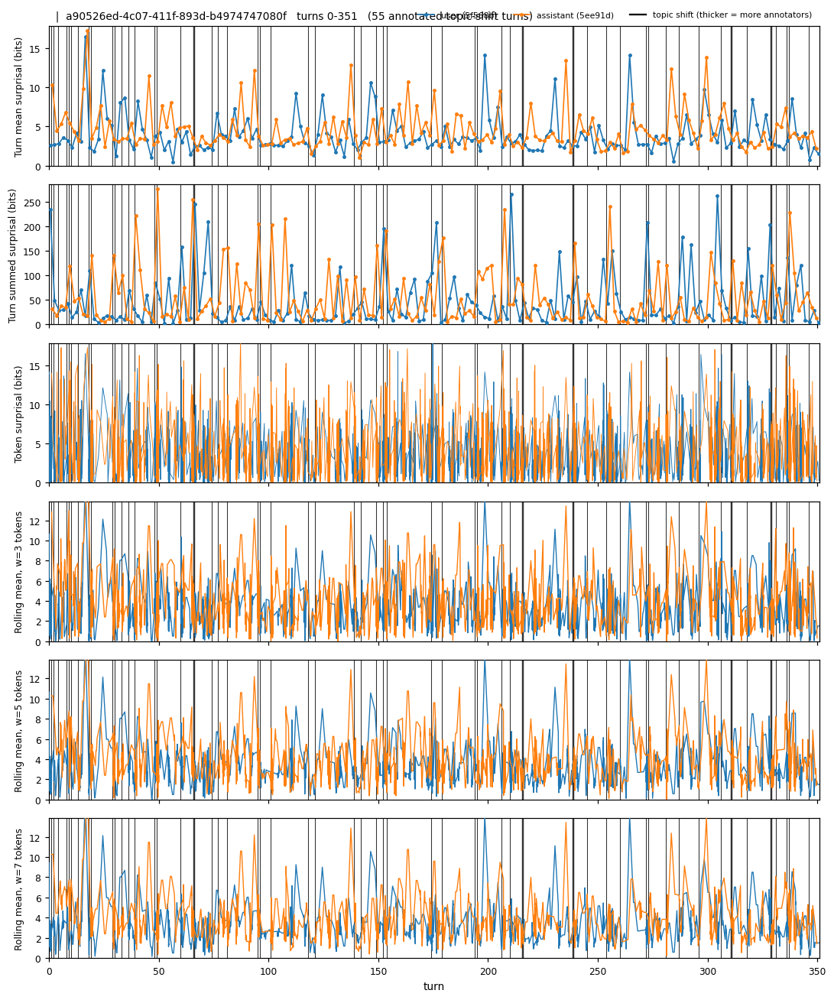

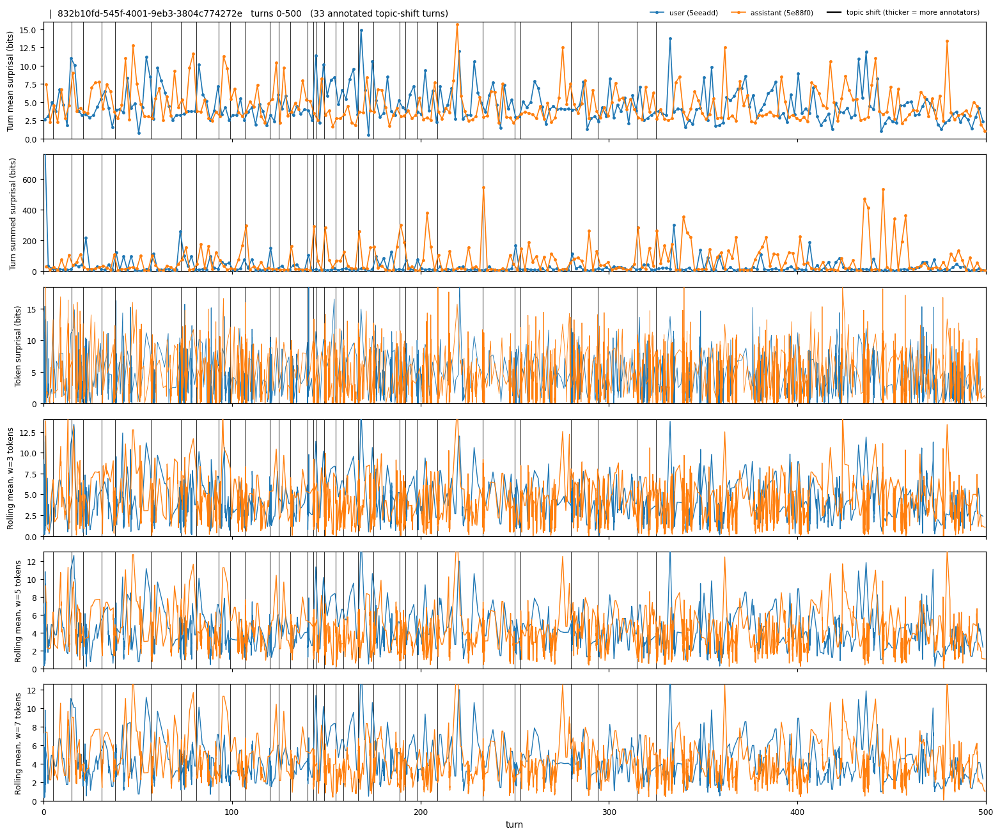

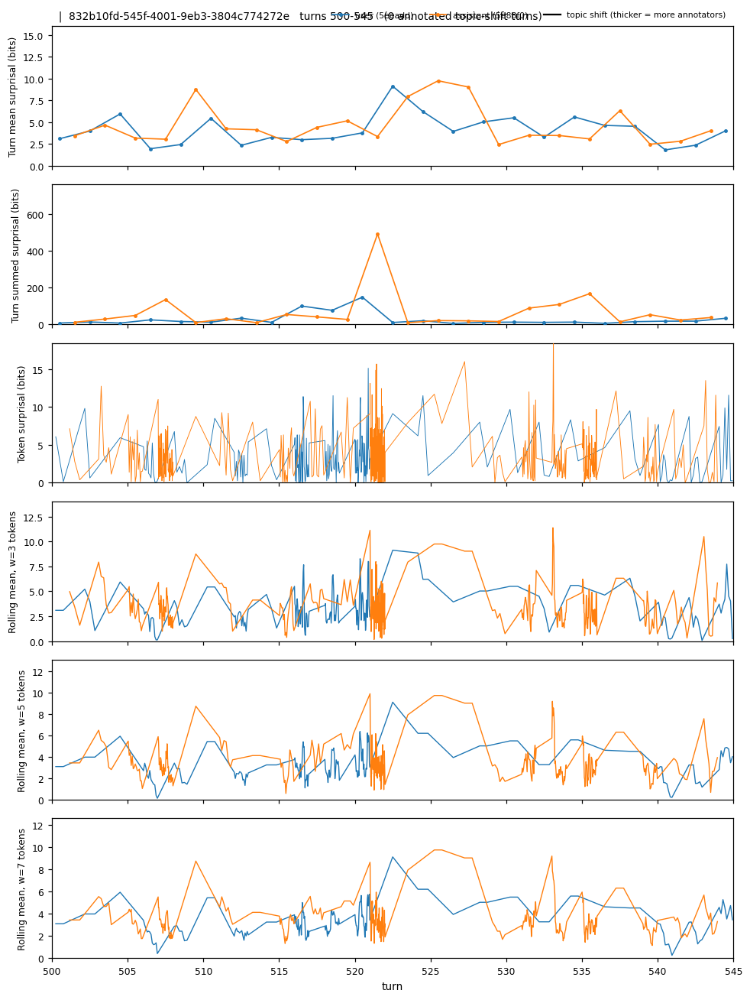

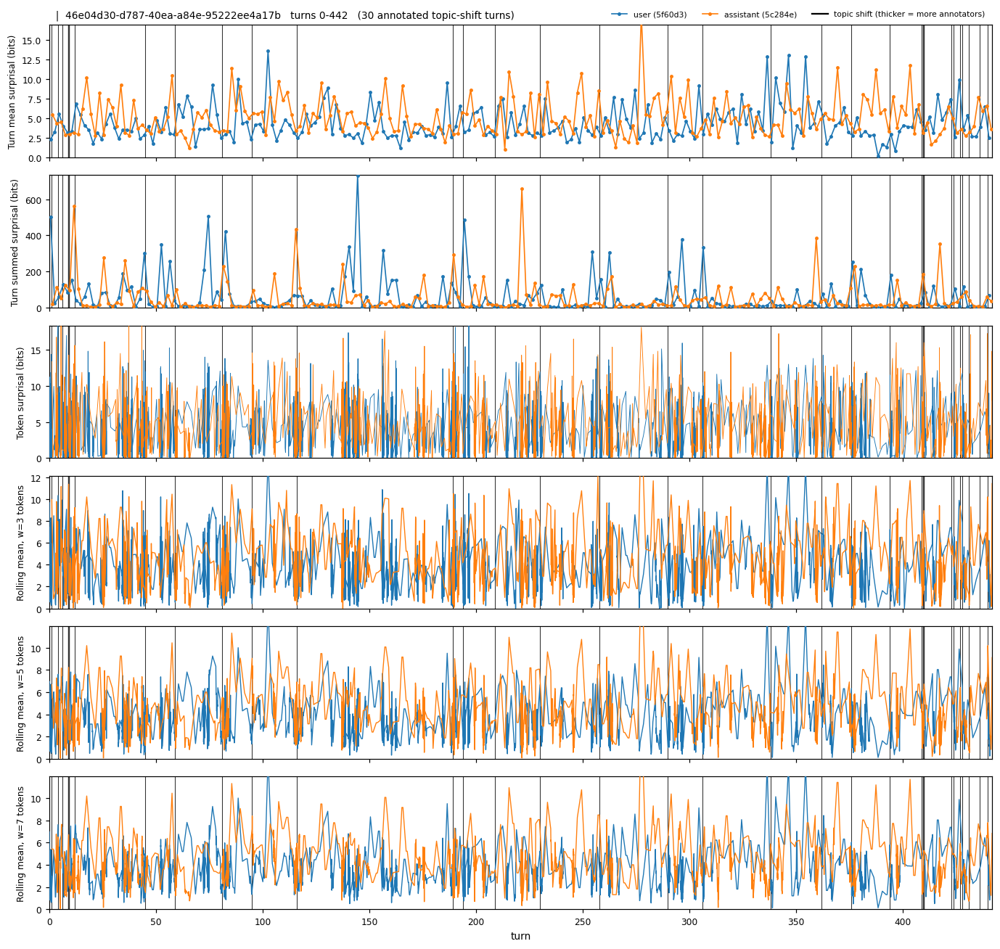

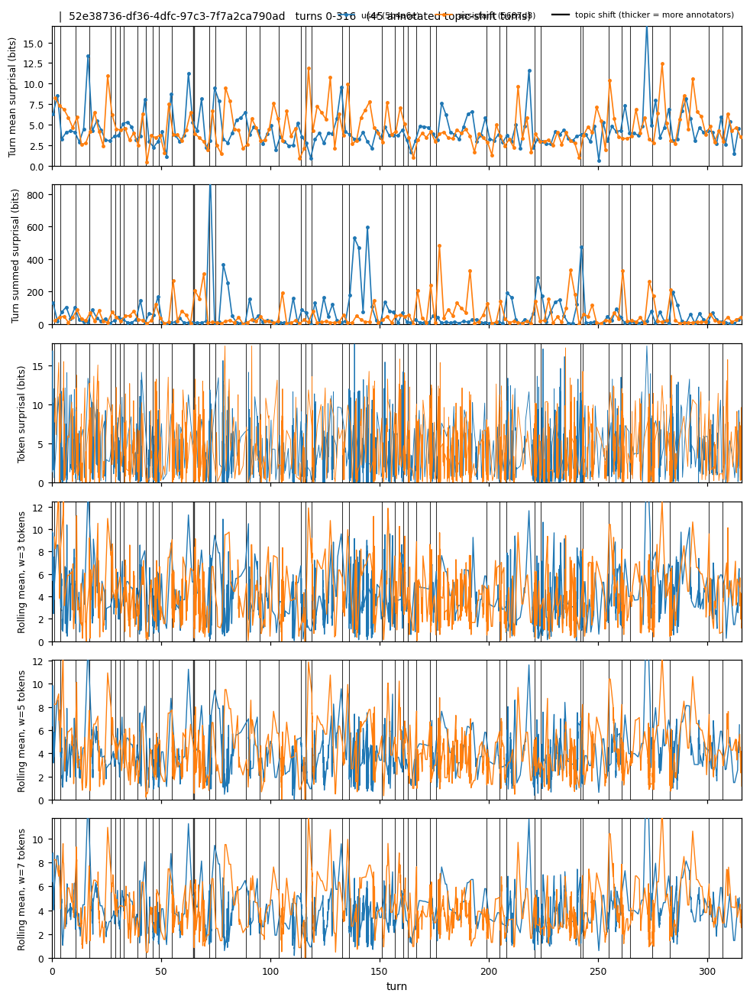

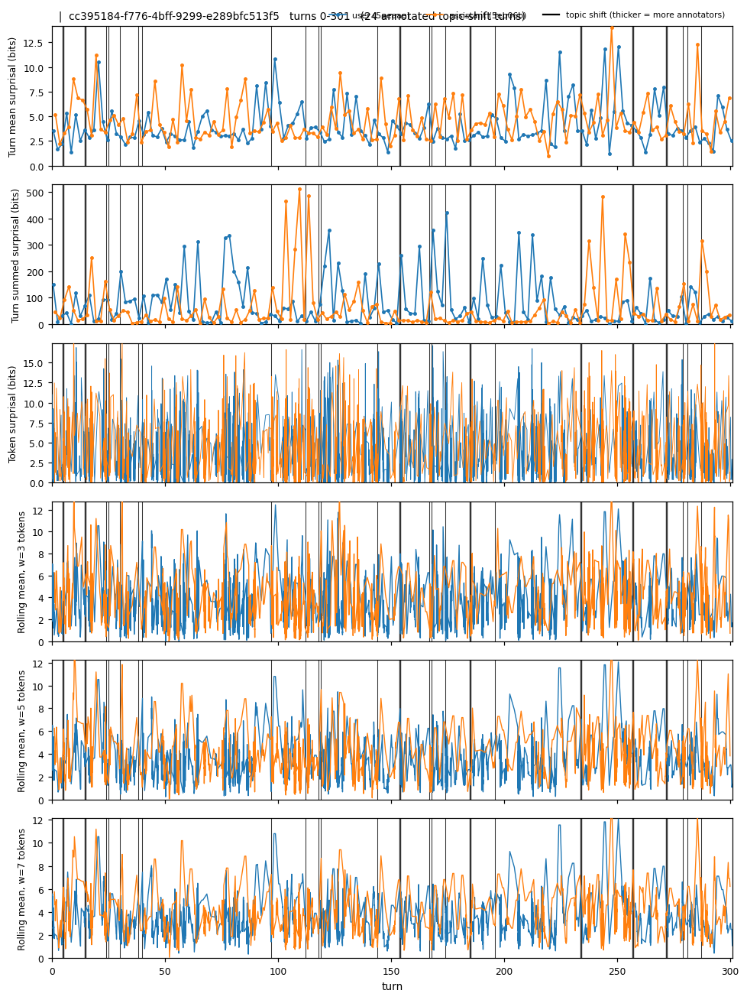

saved line plots for 5 conversations to analysis_out/lineplots


In [8]:
all_ids = list(dict.fromkeys(d["transcript_id"]))
if TRANSCRIPTS:
    ids = TRANSCRIPTS
elif ALL_CONVERSATIONS:
    ids = all_ids
else:
    ids = list(np.random.default_rng(SEED).choice(all_ids, min(N_CONVERSATIONS, len(all_ids)), replace=False))

panels = build_panels(ROLLING, has_pmi)
dtix, ttix = d.groupby("transcript_id").indices, t.groupby("transcript_id").indices
for tid in ids:
    plot_conversation(tid, d.iloc[dtix[tid]], t.iloc[ttix[tid]], marks[marks.transcript_id == tid],
                      panels, OUT / "lineplots", PAGE_TURNS, ZOOM, DPI)
print(f"saved line plots for {len(ids)} conversations to {OUT / 'lineplots'}")

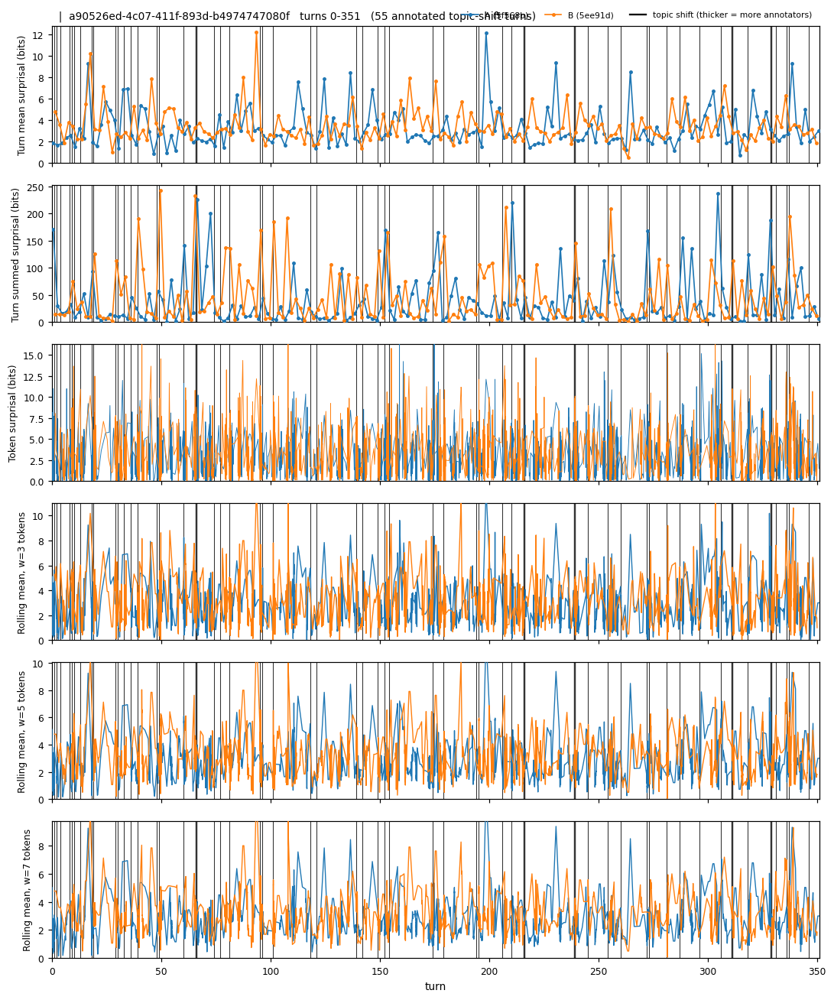

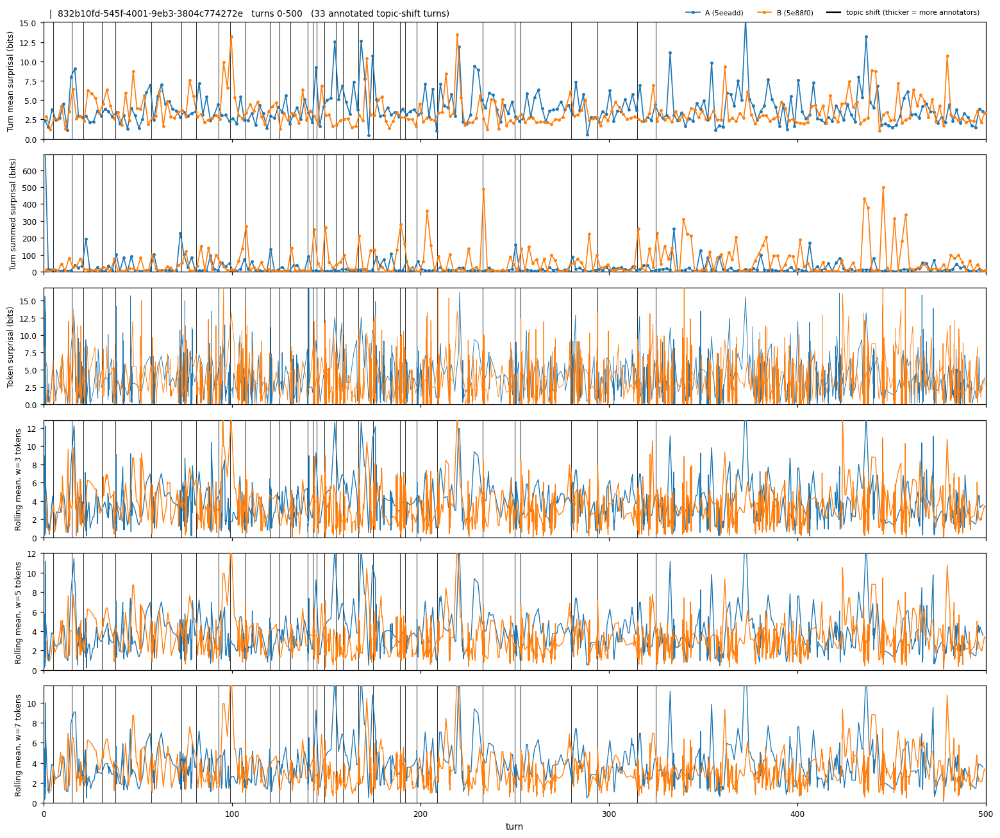

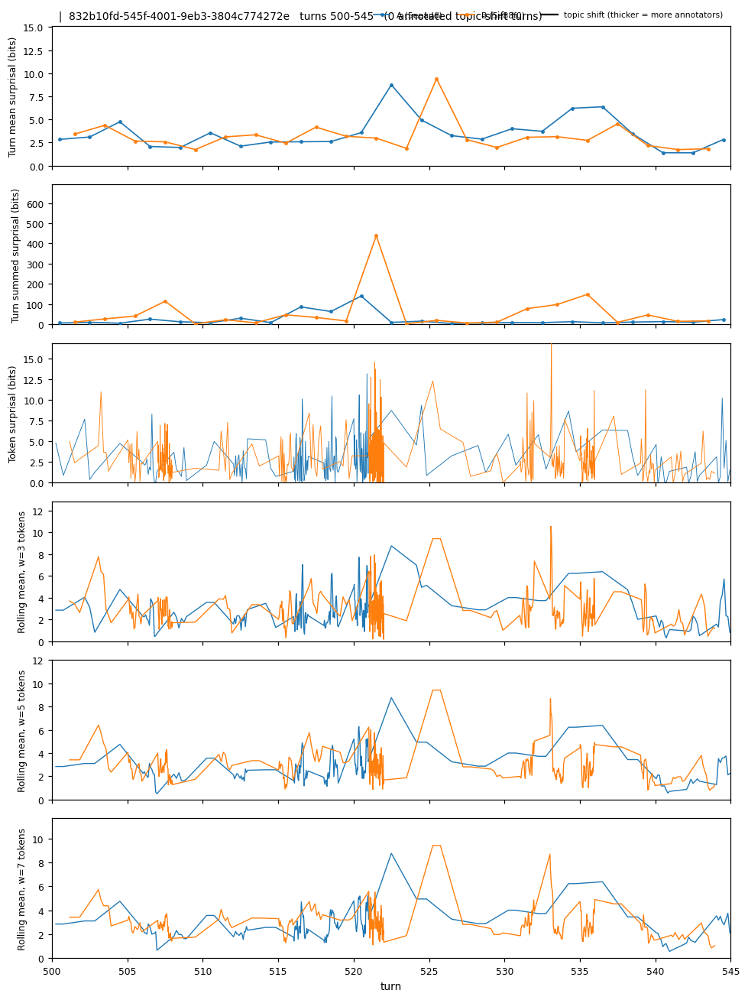

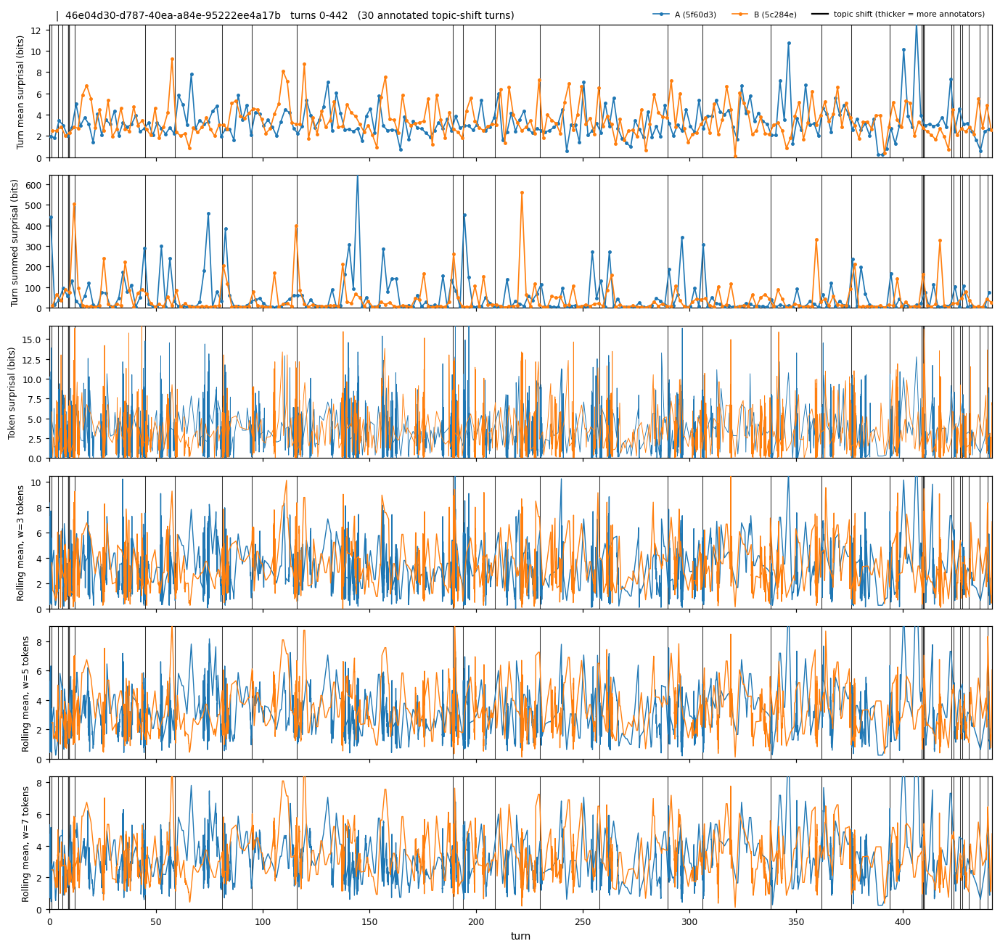

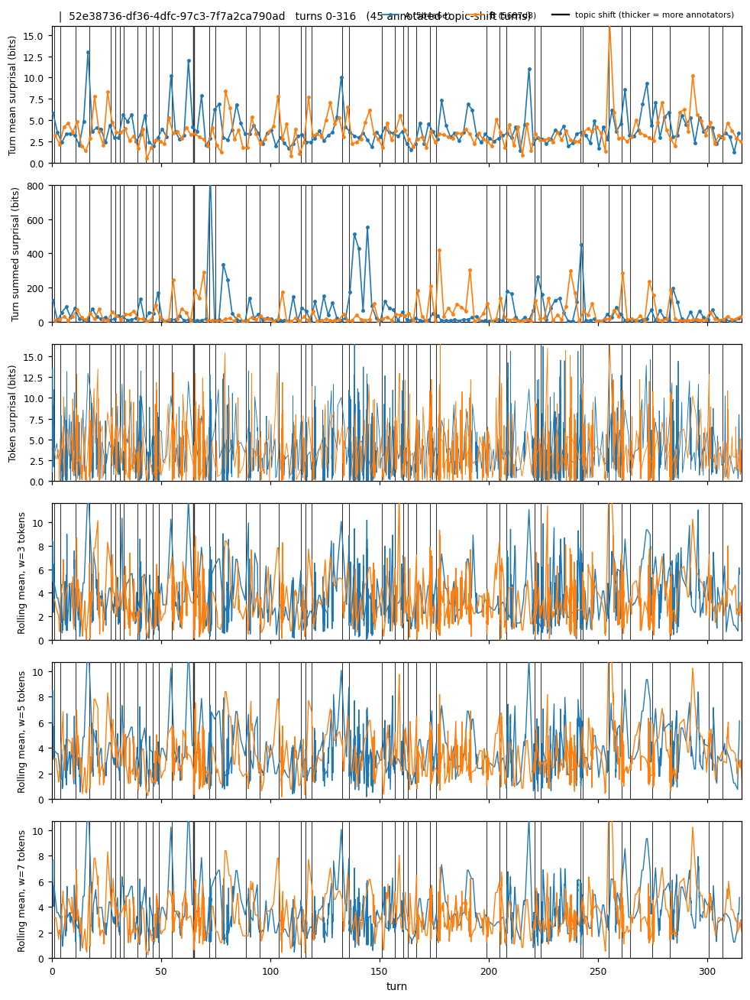

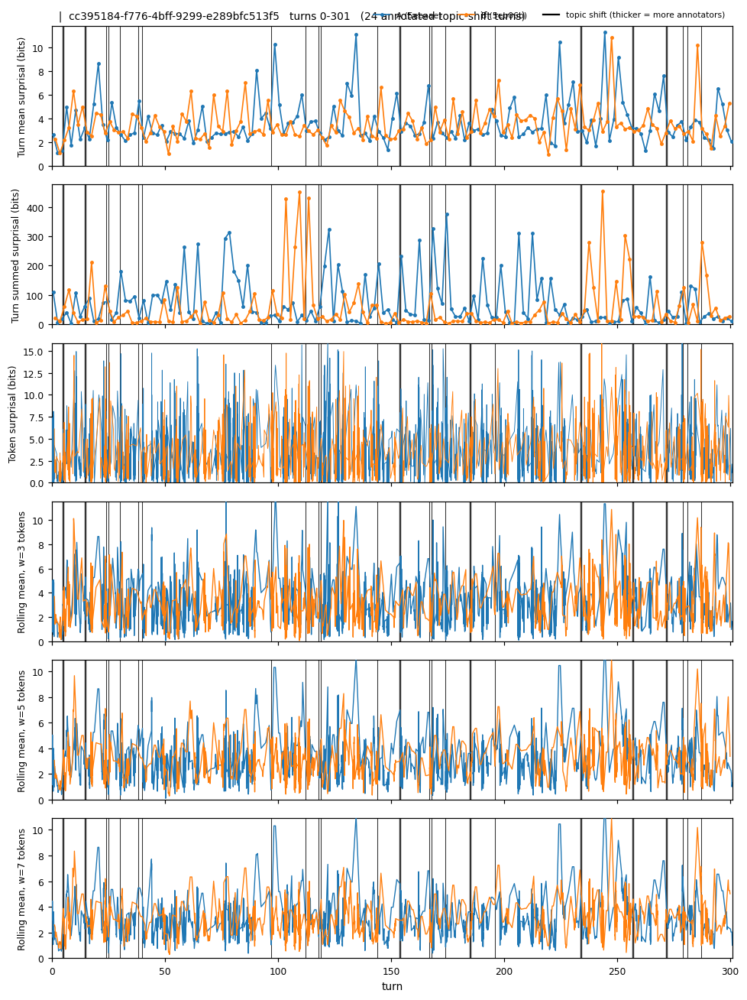

saved line plots for 5 conversations to analysis_out/lineplots


In [24]:
all_ids_base = list(dict.fromkeys(d_base["transcript_id"]))
if TRANSCRIPTS:
    ids_base = TRANSCRIPTS
elif ALL_CONVERSATIONS:
    ids_base = all_ids_base
else:
    ids_base = list(np.random.default_rng(SEED).choice(all_ids_base, min(N_CONVERSATIONS, len(all_ids_base)), replace=False))

panels = build_panels(ROLLING, has_pmi)
dtix, ttix = d_base.groupby("transcript_id").indices, t_base.groupby("transcript_id").indices
for tid in ids_base:
    plot_conversation(tid, d_base.iloc[dtix[tid]], t_base.iloc[ttix[tid]], marks[marks.transcript_id == tid],
                      panels, OUT / "lineplots", PAGE_TURNS, ZOOM, DPI)
print(f"saved line plots for {len(ids_base)} conversations to {OUT / 'lineplots'}")

### Explore a single conversation

Set `TID` and a turn range to zoom in; the full-conversation context and marks are the same as above.

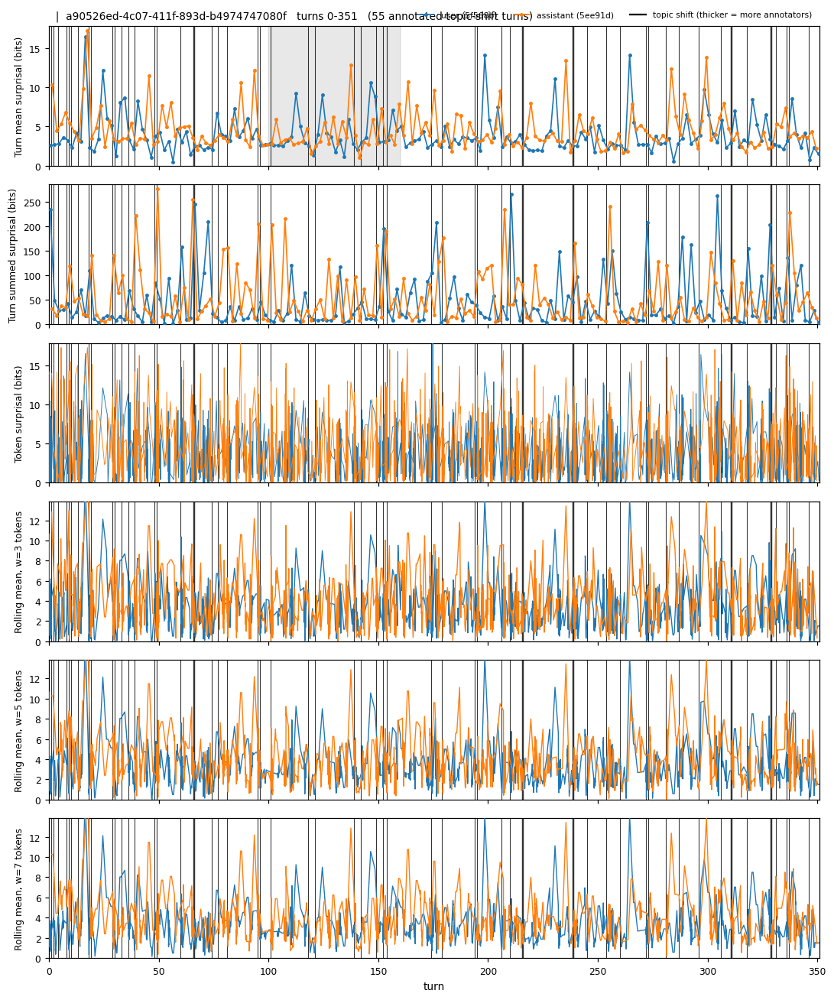

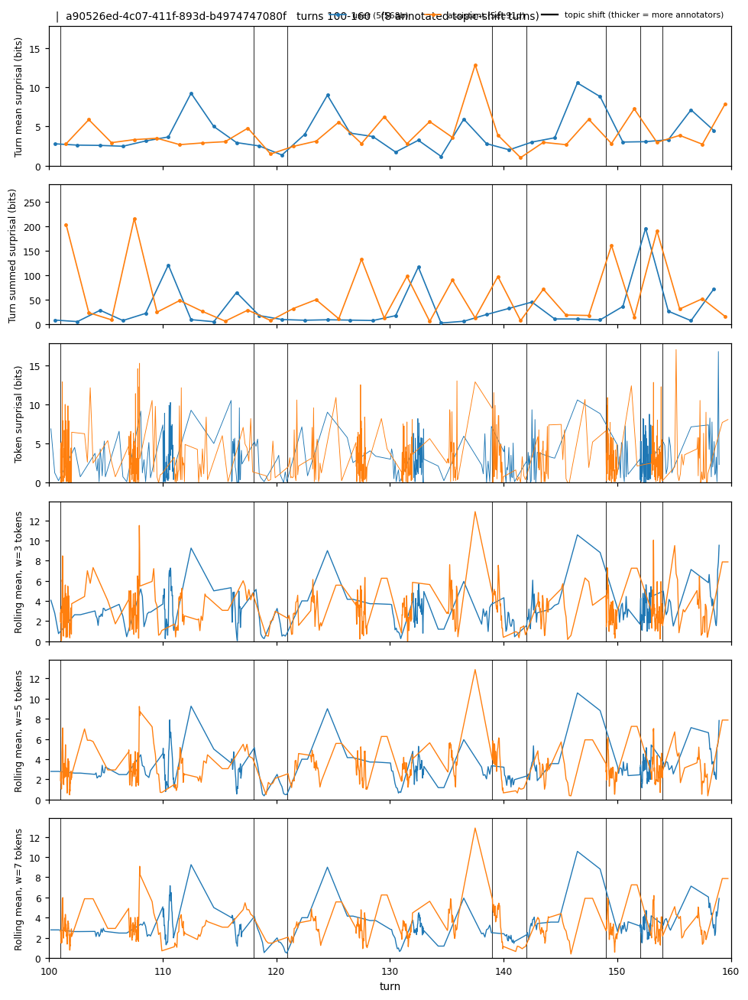

In [9]:
TID  = ids[0]
ZOOM_RANGE = (100, 160)
_shown["n"] = 0          # make sure these figures are displayed

plot_conversation(TID, d.iloc[dtix[TID]], t.iloc[ttix[TID]], marks[marks.transcript_id == TID],
                  panels, OUT / "lineplots", 10**9, ZOOM_RANGE, DPI)

## 4. User vs. assistant role

Panels: (a) token-level ECDF, (b) turn-mean histograms, (c) paired per-conversation means (the right unit for a test), (d) by token position in the turn, (e) over the course of the conversation, (f) turn length (confound check). The role is the first speaker (`user`) vs. second speaker (`assistant`) of each conversation.

In [10]:
def se_band(ax, x, g, color, label):
    m, s, n = g.mean(), g.std(), g.count()
    ax.plot(x, m, color=color, lw=1.4, label=label)
    ax.fill_between(x, m - 1.96 * s / np.sqrt(n), m + 1.96 * s / np.sqrt(n), color=color, alpha=0.2)


def role_figure(d, t, tok_col, turn_col, label, roles, path, dpi):
    cols = {roles[0]: C1, roles[1]: C2}
    fig, ax = plt.subplots(2, 3, figsize=(16, 8.5), dpi=dpi)
    # (a) ECDF of token values
    v = d[tok_col].dropna()
    xmax = np.percentile(v, 99.9)
    for r in roles:
        x = np.sort(d.loc[d.role == r, tok_col].dropna().values)
        ax[0, 0].plot(x, np.arange(1, len(x) + 1) / len(x), color=cols[r], label=f"{r} (n={len(x):,})")
    ax[0, 0].set(xlim=(v.min() if tok_col == "pmi" else 0, xmax), xlabel=f"token {label} (bits)", ylabel="ECDF",
                 title="(a) token-level distribution")
    ax[0, 0].legend(fontsize=8)
    # (b) turn mean histogram
    bins = np.linspace(*np.nanpercentile(t[turn_col], [0.5, 99.5]), 50)
    for r in roles:
        q = t.loc[t.role == r, turn_col].dropna()
        ax[0, 1].hist(q, bins=bins, histtype="step", density=True, color=cols[r], lw=1.6, label=f"{r}")
        ax[0, 1].axvline(q.median(), color=cols[r], ls="--", lw=1)
    ax[0, 1].set(xlabel=f"turn mean {label} (bits)", ylabel="density", title="(b) turn means (dashed = median)")
    ax[0, 1].legend(fontsize=8)
    # (c) paired per-conversation means
    pm = d.groupby(["transcript_id", "role"])[tok_col].mean().unstack().dropna()
    pm = pm[roles]
    for _, r in pm.iterrows():
        ax[0, 2].plot([0, 1], r.values, color="0.7", lw=0.6, zorder=1)
    ax[0, 2].scatter(np.zeros(len(pm)), pm[roles[0]], color=C1, s=10, zorder=2)
    ax[0, 2].scatter(np.ones(len(pm)), pm[roles[1]], color=C2, s=10, zorder=2)
    ax[0, 2].plot([0, 1], pm.mean().values, color="k", lw=2.5, marker="D", zorder=3)
    p = stats.wilcoxon(pm[roles[0]], pm[roles[1]]).pvalue if len(pm) > 5 else np.nan
    ax[0, 2].set(xticks=[0, 1], xticklabels=roles, xlim=(-0.3, 1.3), ylabel=f"mean token {label} (bits)",
                 title=f"(c) per-conversation means, Wilcoxon p={p:.2g}")
    # (d) by token position in turn
    dd = d[d.token_idx < 30]
    for r in roles:
        g = dd[dd.role == r].groupby("token_idx")[tok_col]
        se_band(ax[1, 0], g.mean().index.values, g, cols[r], r)
    ax[1, 0].set(xlabel="token position within turn", ylabel=f"mean {label} (bits)", title="(d) by position in turn")
    ax[1, 0].legend(fontsize=8)
    # (e) by relative position in conversation
    t2 = t.assign(bin=np.minimum((t["rel_pos"] * 10).astype(int), 9))
    for r in roles:
        g = t2[t2.role == r].groupby("bin")[turn_col]
        se_band(ax[1, 1], (g.mean().index.values + 0.5) / 10, g, cols[r], r)
    ax[1, 1].set(xlabel="relative position in conversation", ylabel=f"turn mean {label} (bits)",
                 title="(e) over the course of the conversation")
    # (f) turn length
    bins = np.unique(np.logspace(0, np.log10(max(t["n_tokens"].max(), 2)), 40))
    for r in roles:
        ax[1, 2].hist(t.loc[t.role == r, "n_tokens"], bins=bins, histtype="step", color=cols[r], lw=1.6, label=r)
    ax[1, 2].set(xscale="log", xlabel="tokens per turn", ylabel="turns", title="(f) turn length (confound check)")
    ax[1, 2].legend(fontsize=8)
    fig.suptitle(f"{label}: {roles[0]} vs {roles[1]}   [{RUN_LABEL}]", fontsize=12)
    fig.tight_layout()
    finish(fig, path)


def role_stats(d, t, roles):
    specs = [("token surprisal", d, "surprisal"), ("turn mean surprisal", t, "surprisal_mean"),
             ("turn summed surprisal", t, "surprisal_sum")]
    if d["has_pmi"].iloc[0]:
        specs += [("token PMI", d, "pmi"), ("turn mean PMI", t, "pmi_mean"), ("turn summed PMI", t, "pmi_sum")]
    rows = []
    for name, df, col in specs:
        a = df.loc[df.role == roles[0], col].dropna()
        b = df.loc[df.role == roles[1], col].dropna()
        pm = df.groupby(["transcript_id", "role"])[col].mean().unstack().dropna()
        sd = np.sqrt((a.var() + b.var()) / 2)
        rows.append({"metric": name, f"n_{roles[0]}": len(a), f"n_{roles[1]}": len(b),
                     f"mean_{roles[0]}": a.mean(), f"mean_{roles[1]}": b.mean(),
                     f"median_{roles[0]}": a.median(), f"median_{roles[1]}": b.median(),
                     f"diff_{roles[1]}_minus_{roles[0]}": b.mean() - a.mean(),
                     "cohens_d_pooled_obs": (b.mean() - a.mean()) / sd if sd else np.nan,
                     "mannwhitney_p_pooled(non-indep.)": stats.mannwhitneyu(a, b).pvalue,
                     "n_conversations": len(pm),
                     f"frac_conv_{roles[1]}_higher": (pm[roles[1]] > pm[roles[0]]).mean(),
                     "paired_wilcoxon_p_over_conversations":
                         stats.wilcoxon(pm[roles[0]], pm[roles[1]]).pvalue if len(pm) > 5 else np.nan})
    return pd.DataFrame(rows)

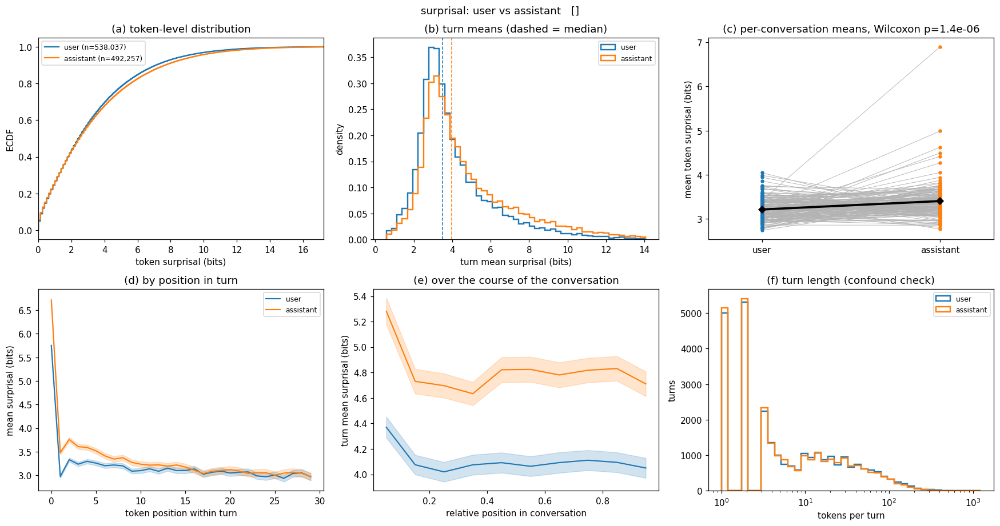

,0,1,2
metric,token surprisal,turn mean surprisal,turn summed surprisal
n_user,538037,28225,28225
n_assistant,492257,28140,28140
mean_user,3.16895,4.104893,60.40787
mean_assistant,3.334397,4.812749,58.32908
median_user,2.4375,3.5,17.5625
median_assistant,2.5,3.984375,19.0
diff_assistant_minus_user,0.165448,0.707855,-2.07879
cohens_d_pooled_obs,0.055347,0.295194,-0.019776
mannwhitney_p_pooled(non-indep.),0.0,0.0,0.0


In [11]:
if len(roles) == 2:
    role_figure(d, t, "surprisal", "surprisal_mean", "surprisal", roles, OUT / "role_comparison_surprisal.png", DPI)
    if has_pmi:
        role_figure(d, t, "pmi", "pmi_mean", "PMI", roles, OUT / "role_comparison_pmi.png", DPI)
    rs = role_stats(d, t, roles)
    rs.to_csv(OUT / "role_stats.csv", index=False)
    display(rs.T)

## 5. Is surprisal sensitive to topic shifts?

Event study around annotated shifts: each turn's metric is z-scored within (conversation × speaker), then averaged at turns −K…+K relative to the shift turn (0 = the turn where the shift is marked).
- **Blue band**: 95% cluster-bootstrap interval over conversations
- **Gray band**: null from random turns (same number of events per conversation)
- Shown for shifts marked by ≥1 and ≥2 annotators. "Starting The Call" shifts are excluded unless `KEEP_START_CALL_SHIFTS`.

In [12]:
def zscore_within(t, col):
    g = t.groupby(["transcript_id", "speaker"])[col]
    sd = g.transform("std").replace(0, np.nan)
    z = (t[col] - g.transform("mean")) / sd
    return z.where(t[col].notna()).fillna(0.0).where(t[col].notna())


def event_curves(series, events, K, B, rng):
    """series: {tid: z array by turn position}; events: {tid: array of event positions}."""
    ks = np.arange(-K, K + 1)
    padded = {tid: np.r_[np.full(K, np.nan), series[tid], np.full(K, np.nan)] for tid in events}

    def gather(tid, pos):
        return padded[tid][pos[:, None] + np.arange(2 * K + 1)[None, :]]

    num, cnt = {}, {}
    for tid, pos in events.items():
        M = gather(tid, pos)
        num[tid], cnt[tid] = np.nansum(M, 0), np.sum(~np.isnan(M), 0)
    tids = list(events)
    N, C = np.array([num[i] for i in tids]), np.array([cnt[i] for i in tids])
    obs = N.sum(0) / np.maximum(C.sum(0), 1)
    boot = []
    for _ in range(B):  # cluster bootstrap over conversations
        ix = rng.integers(0, len(tids), len(tids))
        boot.append(N[ix].sum(0) / np.maximum(C[ix].sum(0), 1))
    boot = np.array(boot)
    nulls = []
    for _ in range(B):  # same number of events per conversation, random positions
        n_, c_ = np.zeros(2 * K + 1), np.zeros(2 * K + 1)
        for tid, pos in events.items():
            M = gather(tid, rng.integers(0, len(series[tid]), len(pos)))
            n_ += np.nansum(M, 0)
            c_ += np.sum(~np.isnan(M), 0)
        nulls.append(n_ / np.maximum(c_, 1))
    return ks, obs, np.percentile(boot, [2.5, 97.5], 0), np.array(nulls)


def topic_event_study(t, K, thresholds, keep_start, B, outdir, dpi, seed):
    rng = np.random.default_rng(seed)
    metrics = [("surprisal_mean", "turn mean surprisal"), ("surprisal_max", "turn max token surprisal")]
    if "pmi_mean" in t:
        metrics.append(("pmi_mean", "turn mean PMI"))
    ev_all = t[t.n_annot > 0]
    if not keep_start:
        ev_all = ev_all[~ev_all.is_start_call]
    rows, thr_used = [], []
    for th in thresholds:
        n_ev = int((ev_all.n_annot >= th).sum())
        if n_ev >= 20:
            thr_used.append(th)
        else:
            print(f"[topic] skipping threshold >= {th} annotators: only {n_ev} events", file=sys.stderr)
    if not thr_used:
        print("[topic] too few annotated topic shifts for an event study", file=sys.stderr)
        return None
    fig, axes = plt.subplots(len(metrics), len(thr_used), figsize=(6.5 * len(thr_used), 3.4 * len(metrics)),
                             dpi=dpi, squeeze=False, sharex=True)
    for i, (col, label) in enumerate(metrics):
        t = t.assign(z=zscore_within(t, col))
        series = {tid: g["z"].values for tid, g in t.groupby("transcript_id")}
        for j, th in enumerate(thr_used):
            ev = ev_all[ev_all.n_annot >= th]
            events = {tid: g["pos"].values for tid, g in ev.groupby("transcript_id")}
            ks, obs, ci, nulls = event_curves(series, events, K, B, rng)
            ax = axes[i, j]
            ax.fill_between(ks, *np.percentile(nulls, [2.5, 97.5], 0), color="0.8", label="null: random turns (95%)")
            ax.fill_between(ks, ci[0], ci[1], color=C1, alpha=0.25)
            ax.plot(ks, obs, color=C1, marker="o", ms=4, label=f"topic shifts (n={sum(map(len, events.values()))})")
            ax.axvline(0, color="k", lw=0.8)
            ax.axhline(0, color="0.5", lw=0.6)
            ax.set(ylabel=f"z({label})", title=f"{label}  |  shift marked by >= {th} annotator(s)")
            ax.legend(fontsize=7)
            # paired shift vs non-shift per conversation
            mark = ev.set_index(KEYS).index
            tt = t.assign(is_ev=t.set_index(KEYS).index.isin(mark))
            pv = tt[tt.transcript_id.isin(events)].groupby(["transcript_id", "is_ev"])["z"].mean().unstack().dropna()
            pw = stats.wilcoxon(pv[True], pv[False]).pvalue if len(pv) > 5 else np.nan
            row = {"metric": col, "min_annotators": th, "n_events": sum(map(len, events.values())),
                   "n_conversations": len(events), "paired_wilcoxon_p_shift_vs_other_turns": pw,
                   "mean_z_shift_minus_other": (pv[True] - pv[False]).mean()}
            for k in (0, 1, 2):
                ix = K + k
                row[f"obs_z_k{k}"] = obs[ix]
                row[f"null_mean_k{k}"] = nulls[:, ix].mean()
                row[f"perm_p_k{k}"] = (1 + np.sum(np.abs(nulls[:, ix] - nulls[:, ix].mean())
                                                 >= abs(obs[ix] - nulls[:, ix].mean()))) / (len(nulls) + 1)
            rows.append(row)
    fig.suptitle(RUN_LABEL, fontsize=10)
    for ax in axes[-1]:
        ax.set_xlabel("turns relative to annotated topic shift (0 = turn where the shift is marked)")
    fig.tight_layout()
    finish(fig, outdir / "topic_event_study.png")
    res = pd.DataFrame(rows)
    res.to_csv(outdir / "topic_shift_stats.csv", index=False)
    return res

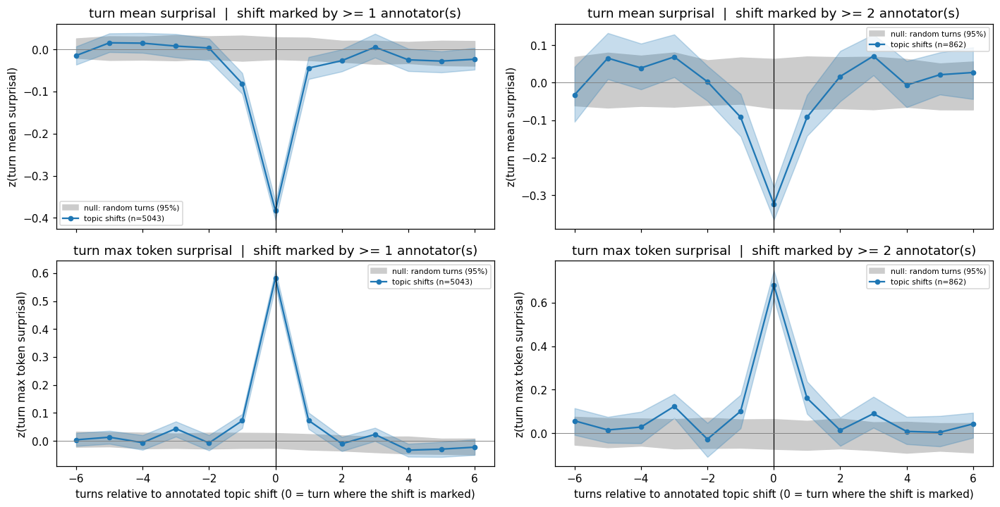

,metric,min_annotators,n_events,n_conversations,paired_wilcoxon_p_shift_vs_other_turns,mean_z_shift_minus_other,obs_z_k0,null_mean_k0,perm_p_k0,obs_z_k1,null_mean_k1,perm_p_k1,obs_z_k2,null_mean_k2,perm_p_k2
0,surprisal_mean,1,5043,154,1.831669e-26,-0.431100,-0.383410,-0.000492,0.003322,-0.044311,0.000368,0.003322,-0.026760,-0.004222,0.086379
1,surprisal_mean,2,862,93,2.567187e-15,-0.343837,-0.323932,-0.002140,0.003322,-0.092235,-0.001163,0.013289,0.016530,-0.001175,0.621262
2,surprisal_max,1,5043,154,1.013827e-25,0.629787,0.582501,0.001478,0.003322,0.073270,-0.004552,0.003322,-0.009668,-0.008477,0.946844
3,surprisal_max,2,862,93,1.099788e-16,0.764409,0.682353,0.000476,0.003322,0.161484,-0.003179,0.003322,0.013575,-0.009720,0.478405


In [13]:
topic_stats = topic_event_study(t, EVENT_WINDOW, MIN_ANNOTATORS, KEEP_START_CALL_SHIFTS, N_RESAMPLES, OUT, DPI, SEED)
topic_stats

## 6. Most surprising tokens

Useful for checking what the spikes in the line plots are (names, numbers, transcription errors, ...).

In [14]:
def top_tokens(d, turns, n, path):
    top = d.nlargest(n, "surprisal")[KEYS + ["speaker", "role", "token_idx", "token", "char_start", "char_end",
                                              "surprisal"] + (["pmi"] if d["has_pmi"].iloc[0] else [])]
    top = top.merge(turns[KEYS + ["utterance"]], on=KEYS, how="left")

    def ctx(r):
        u = r.utterance
        a, b = int(r.char_start), int(r.char_end)
        return f"{u[max(0, a - 50):a]}[[{u[a:b]}]]{u[b:b + 30]}"

    top["context"] = top.apply(ctx, axis=1)
    top = top.drop(columns="utterance")
    top.to_csv(path, index=False)
    return top

In [15]:
top = top_tokens(d, turns, TOP_N, OUT / "top_surprising_tokens.csv")
pd.set_option("display.max_colwidth", 120)
top.head(25)

,transcript_id,turn_id,speaker,role,token_idx,token,char_start,char_end,surprisal,context
0,78d88191-8981-4da8-b232-3e2153d9b599,5,5f5295b28bb79656686ac868,assistant,8,Ġdams,28,33,27.000,Oh that's cool. I love those[[ dams]]
1,6365a56e-c7bc-4f08-9828-08537508f71d,3,593dfb9ea2bf080001ed3b65,assistant,0,correct,0,7,26.000,"[[correct]]. I'm good, how are you,"
2,310ce55b-8db0-4407-a25c-c2460b37cce5,1,5e6fe1df6319c15be2ea3524,assistant,0,yeah,0,4,25.625,[[yeah]] I think this is my third time
3,42d99fff-daee-41bc-ba4a-55b6a787e51d,1,5ed56587e879740cccc9d62a,assistant,0,uh,0,2,25.625,[[uh]] Can you hear me? Yeah.
4,fd31814a-0410-4a33-83ff-cb042367e832,3,5d3213238088eb0018fee4c9,assistant,0,hot,0,3,25.500,[[hot]].
5,c0baec1b-3132-4177-941b-c18aec0be57e,1,5eed8bec94fa2f1be77c189a,assistant,0,power,0,5,25.250,"[[power]]. Our mineral, how"
6,f3eacb84-c7fb-40b8-af8b-4661d9d62a91,9,5bc9f8b677740000016a08b5,assistant,3,ĠGeorgia,6,14,25.250,I'm in[[ Georgia]]. Yeah
7,243349a8-ddca-43f5-bfa7-3ece849fc8e5,1,5f65597823696e0e9bd8f63a,assistant,0,heart,0,5,25.125,[[heart]] pulling
8,46e04d30-d787-40ea-a84e-95222ee4a17b,5,5c284e0970d93a0001211e16,assistant,5,ĠGive,17,22,25.000,"Nice to meet you,[[ Give]] me my name is Brandon."
9,dc4d280b-baf7-4173-aa45-e80b18fc495c,247,5be31317d6e8c40001d00d23,assistant,4,Ġjean,14,19,25.000,"Oh, that sucks[[ jean]]."


## 7. Further analyses

The cells below use the token table `d` and turn table `t` from above and need `statsmodels` (`pip install statsmodels`). The setup cell adds the `questions` / `end_question` columns and a `topic_shift` flag to `t` (topic shifts exclude "Starting The Call"). **Turn 0 is excluded everywhere** because it is often a pooled block of backchannels.

In [16]:
import statsmodels.formula.api as smf      # pip install statsmodels

# columns that `t` does not carry yet
extra = (pd.read_csv(METADATA, dtype={"transcript_id": str}, usecols=KEYS + ["questions", "end_question"])
           .drop_duplicates(KEYS))
t = (t.drop(columns=[c for c in ("questions", "end_question") if c in t])
       .merge(extra, on=KEYS, how="left")
       .sort_values(KEYS).reset_index(drop=True))          # keep turn order (needed for lags)
t["end_question"] = t["end_question"].fillna(False).astype(bool)
t["log_len"] = np.log2(t["n_tokens"])
t["topic_shift"] = (t["n_annot"] > 0) & ~t["is_start_call"]

# Turn 0 is often a pooled block of backchannels (very long, odd timing) -> every analysis below drops it.
print(f"{len(t):,} turns | {int(t.topic_shift.sum()):,} topic-shift turns | "
      f"{int((t.backchannel_count > 0).sum()):,} turns with partner backchannels | "
      f"{int((t.questions > 0).sum()):,} turns with a question")

56,365 turns | 5,043 topic-shift turns | 18,504 turns with partner backchannels | 7,095 turns with a question


### 7a. Constant information rate within turns

If listeners/speakers keep information per token roughly constant given the full context, global surprisal should be flat across token position once the turn-initial spike is removed; a positive slope would mean information accumulates over the turn. Slopes are fitted per turn after dropping the first `SKIP` tokens, then averaged **per conversation** (the unit used for the Wilcoxon test) within turn-length bins. Panels: (a) mean surprisal by absolute position, (b) by relative position, (c) slope by turn length. Rerun with `SKIP = 1, 3, 5` to check sensitivity.

,n_turns,n_conversations,mean_slope_bits_per_100_tokens,ci95_half_width,wilcoxon_p_vs_0
len_bin,,,,,
"[10.0, 20.0)",7137,155,-7.861288,1.015256,6.231995e-23
"[20.0, 40.0)",6358,154,-2.333538,0.282355,2.138570e-24
"[40.0, 80.0)",4544,154,-0.818638,0.120906,4.187138e-21
"[80.0, 160.0)",2251,152,-0.358687,0.053873,1.353323e-20
"[160.0, inf)",619,127,-0.162518,0.047264,1.501137e-10


Spearman(log2 turn length, slope) = 0.169  (p = 2.1e-134; turns are not independent -> see mixed model)


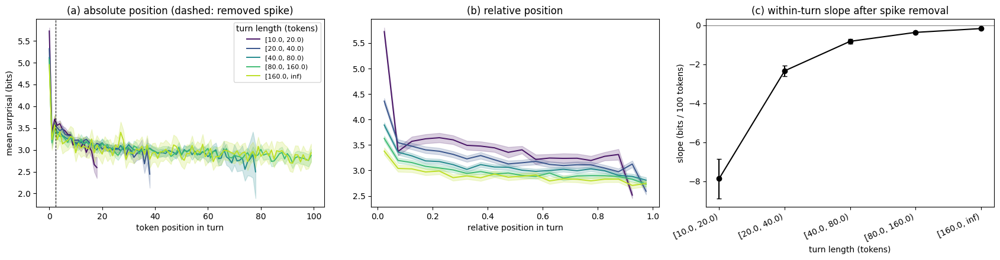

In [17]:
SKIP, MIN_LEN = 3, 10                              # drop first SKIP tokens (initial spike); turns need >= MIN_LEN tokens
BINS = [MIN_LEN, 20, 40, 80, 160, np.inf]

# --- per-turn OLS slope of surprisal on token position (vectorised), after removing the initial spike
dd = d[(d.turn_id > 0) & (d.n_tokens >= MIN_LEN) & (d.token_idx >= SKIP)].copy()
dd["x"] = dd.token_idx - SKIP
g = dd.groupby(KEYS)
dd["dx"] = dd.x - g.x.transform("mean")
dd["dy"] = dd.surprisal - g.surprisal.transform("mean")
dd["sxy"], dd["sxx"] = dd.dx * dd.dy, dd.dx ** 2
sl = (dd.groupby(KEYS).agg(sxy=("sxy", "sum"), sxx=("sxx", "sum"),
                           n_tokens=("n_tokens", "first"), role=("role", "first")).reset_index())
sl["slope100"] = 100 * sl.sxy / sl.sxx             # bits per 100 tokens
sl["len_bin"] = pd.cut(sl.n_tokens, BINS, right=False)

# --- conversations are the unit of inference
conv = sl.groupby(["transcript_id", "len_bin"], observed=True).slope100.mean().unstack()
slope_tab = pd.DataFrame({
    "n_turns": sl.groupby("len_bin", observed=True).size(),
    "n_conversations": conv.notna().sum(),
    "mean_slope_bits_per_100_tokens": conv.mean(),
    "ci95_half_width": 1.96 * conv.sem(),
    "wilcoxon_p_vs_0": conv.apply(lambda v: stats.wilcoxon(v.dropna()).pvalue if v.notna().sum() > 5 else np.nan)})
display(slope_tab)
rho, p = stats.spearmanr(np.log2(sl.n_tokens), sl.slope100)
print(f"Spearman(log2 turn length, slope) = {rho:.3f}  (p = {p:.2g}; turns are not independent -> see mixed model)")

# --- plots: absolute position, relative position, slope by length
tk = d[(d.turn_id > 0) & (d.n_tokens >= MIN_LEN)].copy()
tk["len_bin"] = pd.cut(tk.n_tokens, BINS, right=False)
tk["rel"] = np.minimum((tk.token_idx / tk.n_tokens * 20).astype(int), 19)
cols = plt.cm.viridis(np.linspace(0.05, 0.9, tk.len_bin.nunique()))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for c, (b, q) in zip(cols, tk.groupby("len_bin", observed=True)):
    a = q[q.token_idx < 100].groupby("token_idx").surprisal
    se_band(ax[0], a.mean().index.values, a, c, str(b))
    r = q.groupby("rel").surprisal
    se_band(ax[1], (r.mean().index.values + 0.5) / 20, r, c, str(b))
ax[0].axvline(SKIP - 0.5, color="k", ls="--", lw=0.8)
ax[0].set(xlabel="token position in turn", ylabel="mean surprisal (bits)", title="(a) absolute position (dashed: removed spike)")
ax[1].set(xlabel="relative position in turn", title="(b) relative position")
ax[0].legend(title="turn length (tokens)", fontsize=8)
ax[2].errorbar(range(len(slope_tab)), slope_tab.mean_slope_bits_per_100_tokens, yerr=slope_tab.ci95_half_width,
               fmt="o-", color="k", capsize=3)
ax[2].axhline(0, color="0.5", lw=0.8)
ax[2].set(xticks=range(len(slope_tab)), xticklabels=[str(i) for i in slope_tab.index], xlabel="turn length (tokens)",
          ylabel="slope (bits / 100 tokens)", title="(c) within-turn slope after spike removal")
plt.setp(ax[2].get_xticklabels(), rotation=25, ha="right")
fig.tight_layout(); plt.show()

### 7b. Speaker coupling

Turn mean surprisal is z-scored within (conversation × speaker). Because speakers alternate, **odd turn lags are cross-speaker correlations** and **even lags are autocorrelations of a speaker's own turns**; lag 1 is also split by who speaks first. CIs come from a cluster bootstrap over conversations. The regression asks whether a turn's surprisal predicts the partner's *next* turn beyond the partner's own previous turn, both lengths, and annotated topic shifts (shared topic structure can otherwise produce spurious coupling). Switch `METRIC` to `"pmi_mean"` to look at context-dependence instead.

,lag,kind,subset,n_pairs,r,ci_lo,ci_hi
0,1,cross-speaker,all,56055,-0.030272,-0.043089,-0.018257
1,1,cross-speaker,user -> assistant,27985,-0.022986,-0.037461,-0.008640
2,1,cross-speaker,assistant -> user,28070,-0.037471,-0.053027,-0.022403
3,2,own turns (autocorr.),all,55900,0.057400,0.048216,0.066021
4,3,cross-speaker,all,55745,-0.011145,-0.020832,-0.001946
5,4,own turns (autocorr.),all,55590,0.021768,0.013417,0.029491
6,5,cross-speaker,all,55435,-0.000375,-0.008602,0.008172
7,6,own turns (autocorr.),all,55280,0.009728,0.001176,0.017149
8,7,cross-speaker,all,55126,0.001687,-0.007858,0.011953
9,8,own turns (autocorr.),all,54972,0.009701,0.000120,0.018126


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.5405      0.031     17.704      0.000       0.481       0.600
z             -0.0414      0.008     -5.223      0.000      -0.057      -0.026
z_prev         0.0386      0.004      9.567      0.000       0.031       0.047
log_len        0.0161      0.005      3.357      0.001       0.007       0.026
len_next      -0.2298      0.004    -56.550      0.000      -0.238      -0.222
ts            -0.0257      0.014     -1.838      0.066      -0.053       0.002
ts_next        0.1411      0.012     12.215      0.000       0.118       0.164
coefficient on `z`: partner's next turn vs. this turn, controlling for the partner's own previous turn (z_prev), both lengths and topic shifts


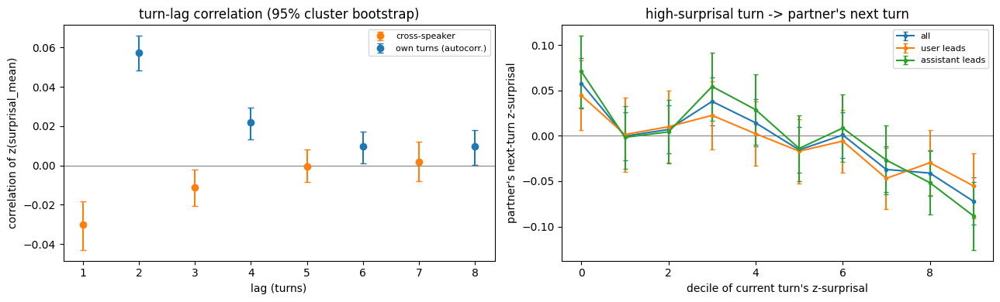

In [18]:
METRIC = "surprisal_mean"                          # or "pmi_mean"
MAXLAG = 8

B = t[t.turn_id > 0].copy()
B["z"] = zscore_within(B, METRIC)                  # z within (conversation x speaker)
B["first_spk"] = B.role == roles[0]
g = B.groupby("transcript_id")

# ---------- lagged correlations over turns -----------------------------------------------------------
# Speakers alternate, so lag k odd = partner's turn, lag k even = same speaker's own later turn:
#   odd lags  -> cross-speaker (lagged cross-correlation);  even lags -> autocorrelation of own turns
def lag_pairs(k):
    y = g.z.shift(-k)
    ok = B.z.notna() & y.notna() & ((g.turn_id.shift(-k) - B.turn_id) == k)        # consecutive turns only
    return pd.DataFrame({"tid": B.transcript_id[ok], "first": B.first_spk[ok], "x": B.z[ok], "y": y[ok]})

def suff(P):                                       # per-conversation sufficient statistics -> fast bootstrap
    P = P.assign(xx=P.x ** 2, yy=P.y ** 2, xy=P.x * P.y, n=1)
    return P.groupby("tid")[["n", "x", "y", "xx", "yy", "xy"]].sum().values

def pooled_r(S):
    n, sx, sy, sxx, syy, sxy = S.sum(0)
    return (n * sxy - sx * sy) / np.sqrt((n * sxx - sx ** 2) * (n * syy - sy ** 2))

def boot_ci(S, nb=1000, seed=0):                   # cluster bootstrap over conversations
    rng = np.random.default_rng(seed)
    return np.percentile([pooled_r(S[rng.integers(0, len(S), len(S))]) for _ in range(nb)], [2.5, 97.5])

rows = []
for k in range(1, MAXLAG + 1):
    P = lag_pairs(k)
    subsets = [("all", P)]
    if k == 1:
        subsets += [(f"{roles[0]} -> {roles[1]}", P[P["first"]]), (f"{roles[1]} -> {roles[0]}", P[~P["first"]])]
    for name, sub in subsets:
        S = suff(sub); lo, hi = boot_ci(S)
        rows.append(dict(lag=k, kind="cross-speaker" if k % 2 else "own turns (autocorr.)", subset=name,
                         n_pairs=int(S[:, 0].sum()), r=pooled_r(S), ci_lo=lo, ci_hi=hi))
lagtab = pd.DataFrame(rows)
display(lagtab)

a = lagtab[lagtab.subset == "all"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for kind, col in [("cross-speaker", C2), ("own turns (autocorr.)", C1)]:
    q = a[a.kind == kind]
    ax[0].errorbar(q.lag, q.r, yerr=[q.r - q.ci_lo, q.ci_hi - q.r], fmt="o", color=col, capsize=3, label=kind)
ax[0].axhline(0, color="0.5", lw=0.8)
ax[0].set(xlabel="lag (turns)", ylabel=f"correlation of z({METRIC})", title="turn-lag correlation (95% cluster bootstrap)")
ax[0].legend(fontsize=8)

# ---------- does a high-surprisal turn predict the partner's NEXT turn? --------------------------------
B["z_prev"], B["z_next"] = g.z.shift(1), g.z.shift(-1)     # z_prev is by the same speaker as z_next
B["len_next"] = g.log_len.shift(-1)
B["ts"] = B.topic_shift.astype(int)                        # shared topic structure can create spurious coupling:
B["ts_next"] = B.groupby("transcript_id").ts.shift(-1)     # control for annotated topic shifts in both turns
consec = ((g.turn_id.shift(-1) - B.turn_id) == 1) & ((B.turn_id - g.turn_id.shift(1)) == 1)
M = B[consec & B[["z", "z_prev", "z_next", "len_next", "ts_next"]].notna().all(axis=1)].copy()
groups = pd.factorize(M.transcript_id)[0]
fit = smf.ols("z_next ~ z + z_prev + log_len + len_next + ts + ts_next", M).fit(cov_type="cluster", cov_kwds={"groups": groups})
print(fit.summary().tables[1])
print("coefficient on `z`: partner's next turn vs. this turn, controlling for the partner's own previous turn (z_prev), both lengths and topic shifts")

M["decile"] = pd.qcut(M.z, 10, labels=False, duplicates="drop")
for who, mk in [("all", np.ones(len(M), bool)), (f"{roles[0]} leads", M.first_spk.values), (f"{roles[1]} leads", ~M.first_spk.values)]:
    gb = M[mk].groupby("decile").z_next
    ax[1].errorbar(gb.mean().index, gb.mean(), yerr=1.96 * gb.sem(), fmt="o-", ms=3, capsize=2, label=who)
ax[1].axhline(0, color="0.5", lw=0.8)
ax[1].set(xlabel="decile of current turn's z-surprisal", ylabel="partner's next-turn z-surprisal",
          title="high-surprisal turn -> partner's next turn")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### 7c. Backchannels and questions

`backchannel_count` is the number of backchannels the **partner** produced during a turn, so the comparison is between turns that received backchannels and those that did not (token timings are not available to localize "before a backchannel"). Questions: `has_question` (≥1 question in the turn), `end_question` (turn ends with a question) and `prev_ends_question` (turn directly follows a question). The table gives raw means, the per-conversation paired difference (Wilcoxon), and a length- and role-adjusted coefficient with SEs clustered by conversation. The plots show the length confound explicitly: short turns have higher mean surprisal and receive fewer backchannels.

/var/folders/fn/6ct_6l112376k8288ws7798m0000gn/T/ipykernel_54583/54132707.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  T["prev_ends_question"] = T.groupby("transcript_id").end_question.shift(1).fillna(False).astype(bool)   # turn answers a question


,flag,metric,n_turns_true,mean_true,mean_false,paired_diff_over_conv,wilcoxon_p,adj_coef,adj_p
0,has_backchannel,surprisal_mean,18462,3.436794,4.958574,-1.498912,3.470277e-27,0.597291,8.934364e-107
1,has_question,surprisal_mean,7006,3.987024,4.525918,-0.456139,1.984384e-21,0.288465,1.204497e-22
2,end_question,surprisal_mean,4194,4.329030,4.469210,0.007461,6.855039e-01,0.096563,1.437598e-02
3,prev_ends_question,surprisal_mean,4192,3.474906,4.538036,-1.000100,5.371693e-27,-0.119729,3.797686e-06


adj_coef: effect of the flag on the turn mean, adjusting for log2 turn length and role (SEs clustered by conversation)


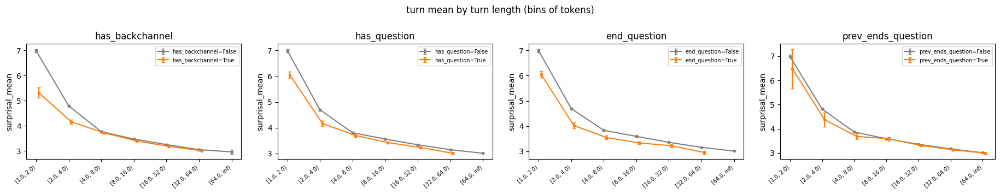

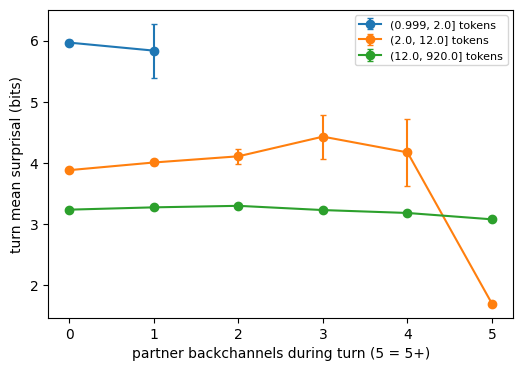

In [19]:
# backchannel_count = number of backchannels the PARTNER produced during this turn (no token timing is available,
# so this compares whole turns that received backchannels with those that did not, not tokens before/after one).
T = t[t.turn_id > 0].copy()
T["has_backchannel"] = T.backchannel_count > 0
T["has_question"] = T.questions > 0
T["prev_ends_question"] = T.groupby("transcript_id").end_question.shift(1).fillna(False).astype(bool)   # turn answers a question
T["role2"] = (T.role == roles[1]).astype(int)
flags = ["has_backchannel", "has_question", "end_question", "prev_ends_question"]
metrics = ["surprisal_mean"] + (["pmi_mean"] if has_pmi else [])
cl = pd.factorize(T.transcript_id)[0]

rows = []
for f in flags:
    for m in metrics:
        pc = T.groupby(["transcript_id", f])[m].mean().unstack().dropna()          # per-conversation means
        fit = smf.ols(f"{m} ~ {f} + log_len + role2", T.assign(**{f: T[f].astype(int)})).fit(
            cov_type="cluster", cov_kwds={"groups": cl})
        rows.append(dict(flag=f, metric=m, n_turns_true=int(T[f].sum()),
                         mean_true=T.loc[T[f], m].mean(), mean_false=T.loc[~T[f], m].mean(),
                         paired_diff_over_conv=(pc[True] - pc[False]).mean(),
                         wilcoxon_p=stats.wilcoxon(pc[True], pc[False]).pvalue if len(pc) > 5 else np.nan,
                         adj_coef=fit.params[f], adj_p=fit.pvalues[f]))
display(pd.DataFrame(rows))
print("adj_coef: effect of the flag on the turn mean, adjusting for log2 turn length and role (SEs clustered by conversation)")

# --- length confound check: short turns have higher mean surprisal (initial-token spike) and receive fewer backchannels
T["len_bin"] = pd.cut(T.n_tokens, [1, 2, 4, 8, 16, 32, 64, np.inf], right=False)
fig, axes = plt.subplots(len(metrics), len(flags), figsize=(4.6 * len(flags), 3.5 * len(metrics)), squeeze=False)
for i, m in enumerate(metrics):
    for j, f in enumerate(flags):
        ax = axes[i, j]
        for val, col in [(False, "0.5"), (True, C2)]:
            gb = T[T[f] == val].groupby("len_bin", observed=True)[m]
            ax.errorbar(np.arange(len(gb.mean())) + 0.08 * val, gb.mean(), yerr=1.96 * gb.sem(), fmt="o-", ms=3,
                        color=col, capsize=2, label=f"{f}={val}")
        ax.set(xticks=range(T.len_bin.nunique()), xticklabels=[str(b) for b in T.len_bin.cat.categories], ylabel=m,
               title=f if i == 0 else "")
        plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=7)
        ax.legend(fontsize=7)
fig.suptitle("turn mean by turn length (bins of tokens)", y=1.0); fig.tight_layout(); plt.show()

# --- dose-response: number of partner backchannels during the turn, within length terciles
T["bc_cap"] = T.backchannel_count.clip(upper=5)
T["len_tercile"] = pd.qcut(T.n_tokens, 3, duplicates="drop")
fig, ax = plt.subplots(figsize=(6, 4))
for lab, q in T.groupby("len_tercile", observed=True):
    gb = q.groupby("bc_cap").surprisal_mean
    ax.errorbar(gb.mean().index, gb.mean(), yerr=1.96 * gb.sem(), fmt="o-", capsize=2, label=f"{lab} tokens")
ax.set(xlabel="partner backchannels during turn (5 = 5+)", ylabel="turn mean surprisal (bits)")
ax.legend(fontsize=8); plt.show()

### 7d. Mixed-effects regression

Token level: `surprisal ~ first_tok + log-position × log-turn-length + second_speaker + topic_shift` with crossed random intercepts for conversation and speaker (speakers recur across conversations, so they are not nested). statsmodels' crossed random effects are slow, so the model is fitted on a random sample of `MAX_ROWS` tokens; the clustered OLS on all tokens is a fast complement, and the turn-level model uses all turns. Check `converged` and lower `MAX_ROWS` or use the `lmer` formula in the cell if it does not finish.

In [20]:
MAX_ROWS, SEED = 100_000, 0       # statsmodels' crossed random effects are slow: fit on a random token sample ...

tok = d[d.turn_id > 0].merge(t[KEYS + ["topic_shift"]], on=KEYS, how="left")
tok["topic_shift"] = tok.topic_shift.astype(int)
tok["second_speaker"] = (tok.role == roles[1]).astype(int)          # 0 = first speaker ("user"), 1 = second ("assistant")
tok["first_tok"] = (tok.token_idx == 0).astype(int)                 # turn-initial spike
tok["lpos_c"] = np.log1p(tok.token_idx) - np.log1p(tok.token_idx).mean()   # position (log), centred
tok["llen_c"] = np.log2(tok.n_tokens) - np.log2(tok.n_tokens).mean()       # turn length (log2), centred
tok["one"] = 1                                                      # single dummy group -> crossed variance components

formula = "surprisal ~ first_tok + lpos_c * llen_c + second_speaker + topic_shift"
vc = {"conversation": "0 + C(transcript_id)", "speaker": "0 + C(speaker)"}   # speakers recur across conversations: crossed

sub = tok.sample(min(MAX_ROWS, len(tok)), random_state=SEED)
mm = smf.mixedlm(formula, sub, groups="one", vc_formula=vc, re_formula="0").fit(method=["lbfgs", "powell"])
print("converged:", mm.converged)       # if False: lower MAX_ROWS, drop the speaker term, or use the lmer equivalent below
print(mm.summary())
# `lpos_c`: surprisal change per log-position beyond the first token; `lpos_c:llen_c`: does that slope depend on turn length?
# `topic_shift` and turn length are turn-level predictors repeated over tokens, so token-level SEs are optimistic;
# the turn-level model further below is the cleaner test for those two.

# --- fast complement on ALL tokens: OLS with SEs clustered by conversation (no random intercepts)
ols = smf.ols(formula, tok).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(tok.transcript_id)[0]})
print(ols.summary().tables[1])

# --- the same questions at turn level (one row per turn), where the full data is feasible
tt = t[t.turn_id > 0].copy()
tt["second_speaker"] = (tt.role == roles[1]).astype(int)
tt["llen_c"] = tt.log_len - tt.log_len.mean()
tt["topic_shift"] = tt.topic_shift.astype(int)
tt["one"] = 1
mt = smf.mixedlm("surprisal_mean ~ llen_c + second_speaker + topic_shift + rel_pos", tt, groups="one",
                 vc_formula=vc, re_formula="0").fit(method=["lbfgs", "powell"])
print("converged:", mt.converged)
print(mt.summary())

# Scalable equivalent in R (also lets you add a random intercept for turn, which token-level data really needs):
#   lmer(surprisal ~ first_tok + lpos_c * llen_c + second_speaker + topic_shift + (1|transcript_id) + (1|speaker), data = tok)

/opt/anaconda3/envs/understanding_llms/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


converged: True
           Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable: surprisal   
No. Observations:  100000   Method:             REML        
No. Groups:        1        Scale:              8.3149      
Min. group size:   100000   Log-Likelihood:     -248127.9581
Max. group size:   100000   Converged:          Yes         
Mean group size:   100000.0                                 
------------------------------------------------------------
                 Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------
Intercept         2.974    0.062  47.972 0.000  2.852  3.095
first_tok         2.486    0.056  44.177 0.000  2.376  2.596
lpos_c           -0.147    0.013 -11.644 0.000 -0.171 -0.122
llen_c            0.001    0.010   0.055 0.956 -0.019  0.021
lpos_c:llen_c     0.029    0.004   7.137 0.000  0.021  0.037
second_speaker    0.169    0.023   7.309 0.000  0.123  0.214
topic_shift       0.

/opt/anaconda3/envs/understanding_llms/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/understanding_llms/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with powell
  warnings.warn(
/opt/anaconda3/envs/understanding_llms/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


converged: True
            Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: surprisal_mean
No. Observations:  56210   Method:             REML          
No. Groups:        1       Scale:              4.2917        
Min. group size:   56210   Log-Likelihood:     -120900.4871  
Max. group size:   56210   Converged:          Yes           
Mean group size:   56210.0                                   
-------------------------------------------------------------
                 Coef.  Std.Err.    z     P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept         4.214    0.029  143.098 0.000  4.156  4.271
llen_c           -0.583    0.005 -127.259 0.000 -0.592 -0.574
second_speaker    0.656    0.032   20.657 0.000  0.594  0.718
topic_shift       0.311    0.033    9.425 0.000  0.246  0.376
rel_pos          -0.174    0.030   -5.729 0.000 -0.233 -0.114
conversation Var  0.005    0.002                             
spea

## 8. Remaining ideas

1. **Context-length curve**: score each turn with only the last *k* turns (k = 0, 1, 2, 4, 8, all) to see how far back useful information reaches (needs re-scoring).
2. **Bits per second**: `t["bits_per_sec"]` against speech rate, pauses (`interval`, `delta`) and overlap.
3. **Topic structure**: new topic vs. return to an earlier topic; time since a topic was last discussed.
4. **Lexical repetition**: surprisal of tokens repeated from the partner's previous turn (priming).
5. **Fillers and repairs**: "um"/"uh" and disfluencies vs. content words.
6. **Model comparison**: base vs. instruct, size, chat template vs. plain format.